# La polarisation politique en Europe : position, extrémité et alignement des opinions (ESS11)

*Projet de Python pour la data science — ENSAE, 1re année, 2026*

**Auteurs :** [Prénom Nom] · [Prénom Nom] · [Prénom Nom]

### Sommaire

- [Introduction](#intro)
- [Partie 1 — Récupération, nettoyage et enrichissement des données](#partie1)
- [Partie 2 — Polarisation et attitudes : une cartographie des corrélations](#partie2)
- [Partie 3 — Mécanisme de l'alignement et dynamique selon l'âge](#partie3)
- [Conclusion](#conclusion)
- [Références](#references)

<a id="intro"></a>
## Introduction

On entend souvent que les sociétés européennes se « polarisent ». Mais ce mot peut vouloir dire deux choses différentes :
- **les gens deviennent plus extrêmes** : plus de personnes se placent très à gauche ou très à droite ;
- **les opinions s'alignent** : les personnes de gauche (ou de droite) pensent de plus en plus la même chose sur des sujets très différents (immigration, mœurs, redistribution, climat…).

**Problématique.** *À quoi la position gauche-droite et l'extrémité politique des Européens sont-elles liées, et ces liens varient-ils selon les pays et selon l'âge ?*

**Données.** Nous utilisons la 11e vague de l'*European Social Survey* (ESS11, 2023-2024), enrichie avec des données sur les partis (PartyFacts, ParlGov) et sur les pays (API Eurostat). Deux mesures de polarisation servent de fil rouge : la **position** `lrscale` (0 = gauche, 10 = droite) et l'**extrémité** `lrscaleabs` $= |\text{lrscale} - 5|$.

**Trois articles de référence**, dont nous reproduisons une figure :
- **DellaPosta, Shi et Macy (2015)** : les opinions sur des sujets sans lien logique finissent par aller ensemble ;
- **Baldassarri et Gelman (2008)** : la polarisation peut venir de l'alignement des opinions, sans que les gens deviennent plus extrêmes ;
- **Kozlowski et Murphy (2021)** : l'alignement des opinions sur le camp politique s'est renforcé aux États-Unis ; nous adaptons leur méthode aux tranches d'âge.

**Plan.**
1. **Partie 1** : récupération, nettoyage et enrichissement des données.
2. **Partie 2** : quelles opinions sont liées à la position et à l'extrémité, et ces liens sont-ils les mêmes dans tous les pays ?
3. **Partie 3** : comment l'alignement produit de la polarisation, et comment il varie selon l'âge.

Le code long est rangé dans le dossier `scripts/` (un fichier par partie, plus `outils.py` pour les fonctions communes) ; ce notebook appelle ces fonctions et commente les résultats.

In [1]:
# À exécuter une fois (le package eurostat n'est pas installé par défaut sur Onyxia)
%pip install --quiet -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from scripts import donnees, correlations, alignement

pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 2)

<a id="partie1"></a>
## Partie 1 – Récupération, nettoyage et enrichissement des données ESS11

Cette partie part du fichier brut ESS11 (https://ess.sikt.no/en/datafile/242aaa39-3bbb-40f5-98bf-bfb1ce53d8ef), l'enrichit avec d'autres bases de données et produit :

1. une **heatmap des valeurs manquantes** par pays et par variable, qui permet de choisir les variables ou les pays à exclure 
2. un **retraitement des données** : codes de non-réponse (NaN), recodage, normalisation sur [0, 1], renommage, conversion des types 
3. de **nouvelles variables politiques** : `lrscale`, `lrscaleabs` et `politiscale`, ainsi que des groupes thématiques 
4. un **enrichissement** : partis votés (PartyFacts + ParlGov) et données pays (API Eurostat). Cela permet d'enrichir la base de données publique ESS11
5. un **fichier propre** `data/ess11_propre.csv` et un dictionnaire des variables

#### Fichiers de données

Les fichiers sont publics, dans le bucket personnel de gleguestensae

- `ESS11e04_2.csv` : fichier intégré ESS11, édition 4.2 (https://ess.sikt.no/en/datafile/242aaa39-3bbb-40f5-98bf-bfb1ce53d8ef)
- `essprt-all.csv` : table PartyFacts des partis de l'ESS (https://github.com/hdigital/partyfactsdata/blob/main/import/essprtv/essprt-all.csv)
- `partyfacts-external-parties.csv` : table de liens de PartyFacts entre toutes les bases de partis (page *Download* du site PartyFacts, fichier external parties)
- `view_party.csv` : table des partis de ParlGov (https://dataverse.harvard.edu/dataset.xhtml?persistentId=doi:10.7910/DVN/2VZ5ZC)

Toutes les données (brutes, externes et produites) sont rangées dans `data/`, qui n'est pas envoyé sur GitHub (fichiers trop lourds). Les figures sont enregistrées dans `figures/`. Les fonctions de cette partie sont dans `scripts/donnees.py`.

### 1.0 Récupération des fichiers

Les datas sont en public sur Onyxia, on part donc du principe que le code est exécuté depuis un de ces serveurs : sinon, il faut manuellement importer les datas ( qui sont fournies en pièce jointe du mail, github limitant à 25 Mo ). 

Une solution plus générale est complexe à mettre en place : nous ne disposons pas des permissions d'accès au fichier `diffusion/` d'Onyxia, et les données de l'ESS11 sont en téléchargement libre, pas en accès libre.

In [3]:
donnees.recuperer_donnees()

Déjà présent : data/ESS11e04_2.csv
Déjà présent : data/externes/essprt-all.csv
Déjà présent : data/externes/partyfacts-external-parties.csv
Déjà présent : data/externes/view_party.csv


### 1.1 Chargement des données

In [4]:
brut = donnees.charger_ess()

50,116 répondants, 691 colonnes, 30 pays


### 1.2 Dictionnaire des variables

On ne garde que les variables qui se rangent dans des groupes pertinants : le questionnaire ESS11 comporte énormément de questions subsidiaires auxquelles nous ne nous intéresserons pas dans cette étude.

On retravaille chaque variable ESS :
- `nom` : nouveau nom lisible 
- `vmin`, `vmax` : bornes valides de l'échelle. Tout ce qui est en dehors (7/8/9, 77/88/99, 55, 6666...) correspond à un code de non-réponse et devient NaN (Dans ESS11, les codes de non réponse varient)
- `inverser` : `True` si l'échelle doit être retournée pour qu'une valeur haute ait le sens indiqué en commentaire de chaque groupe ( Utile dans la seconde partie : il est important qu'une valeur élevée pour une variable soit systématiquement associée à un profil "favorable au changement", dans l'ordre des groupes : plus favorable à l'immigration / plus libéral / plus égalitaire / plus préoccupé par le climat / plus confiant / plus satisfait / plus religieux / en meilleure santé / plus politisé)
- `groupe` : groupe thématique 

`lrscale` reste sur son échelle d'origine : 0 = gauche, 10 = droite.

In [5]:
# Aperçu du dictionnaire (complet dans scripts/donnees.py, variable VARIABLES)
pd.DataFrame(donnees.VARIABLES).T.head(10)

,nom,vmin,vmax,inverser,groupe
imsmetn,immig_meme_ethnie,1,4,True,immigration
imdfetn,immig_autre_ethnie,1,4,True,immigration
impcntr,immig_pays_pauvres,1,4,True,immigration
imbgeco,immig_economie,0,10,False,immigration
imueclt,immig_culture,0,10,False,immigration
imwbcnt,immig_pays_meilleur,0,10,False,immigration
freehms,lgbt_libre,1,5,True,lgbt_moeurs
hmsfmlsh,lgbt_pas_honte,1,5,False,lgbt_moeurs
hmsacld,lgbt_adoption,1,5,True,lgbt_moeurs
gincdif,redistrib_reduire_inegalites,1,5,True,redistribution


#### Variables sociodémographiques

In [6]:
# nouveau nom, borne min, borne max
donnees.SOCIODEMO

{'agea': ('age', 15, 110),
 'yrbrn': ('annee_naissance', 1900, 2012),
 'gndr': ('genre_resp', 1, 2),
 'eisced': ('education_isced', 1, 7),
 'eduyrs': ('annees_etudes', 0, 40),
 'hinctnta': ('revenu_decile', 1, 10),
 'domicil': ('lieu_vie', 1, 5)}

### 1.3 Codes de non-réponse

Pour `lrscale`, on garde "ne sait pas" (code 88) dans une indicatrice `lrscale_nsp` : ne pas savoir se placer est un signe de faible politisation.

In [7]:
df = donnees.codes_manquants_vers_nan(brut)

### 1.4 Heatmap des valeurs manquantes par pays (figure 1)

Une case = part de répondants d'un pays sans réponse valide à une variable. L'objectif de cette section est de vérifier si certains pays ou certaines questions sont vides : on les retire alors.

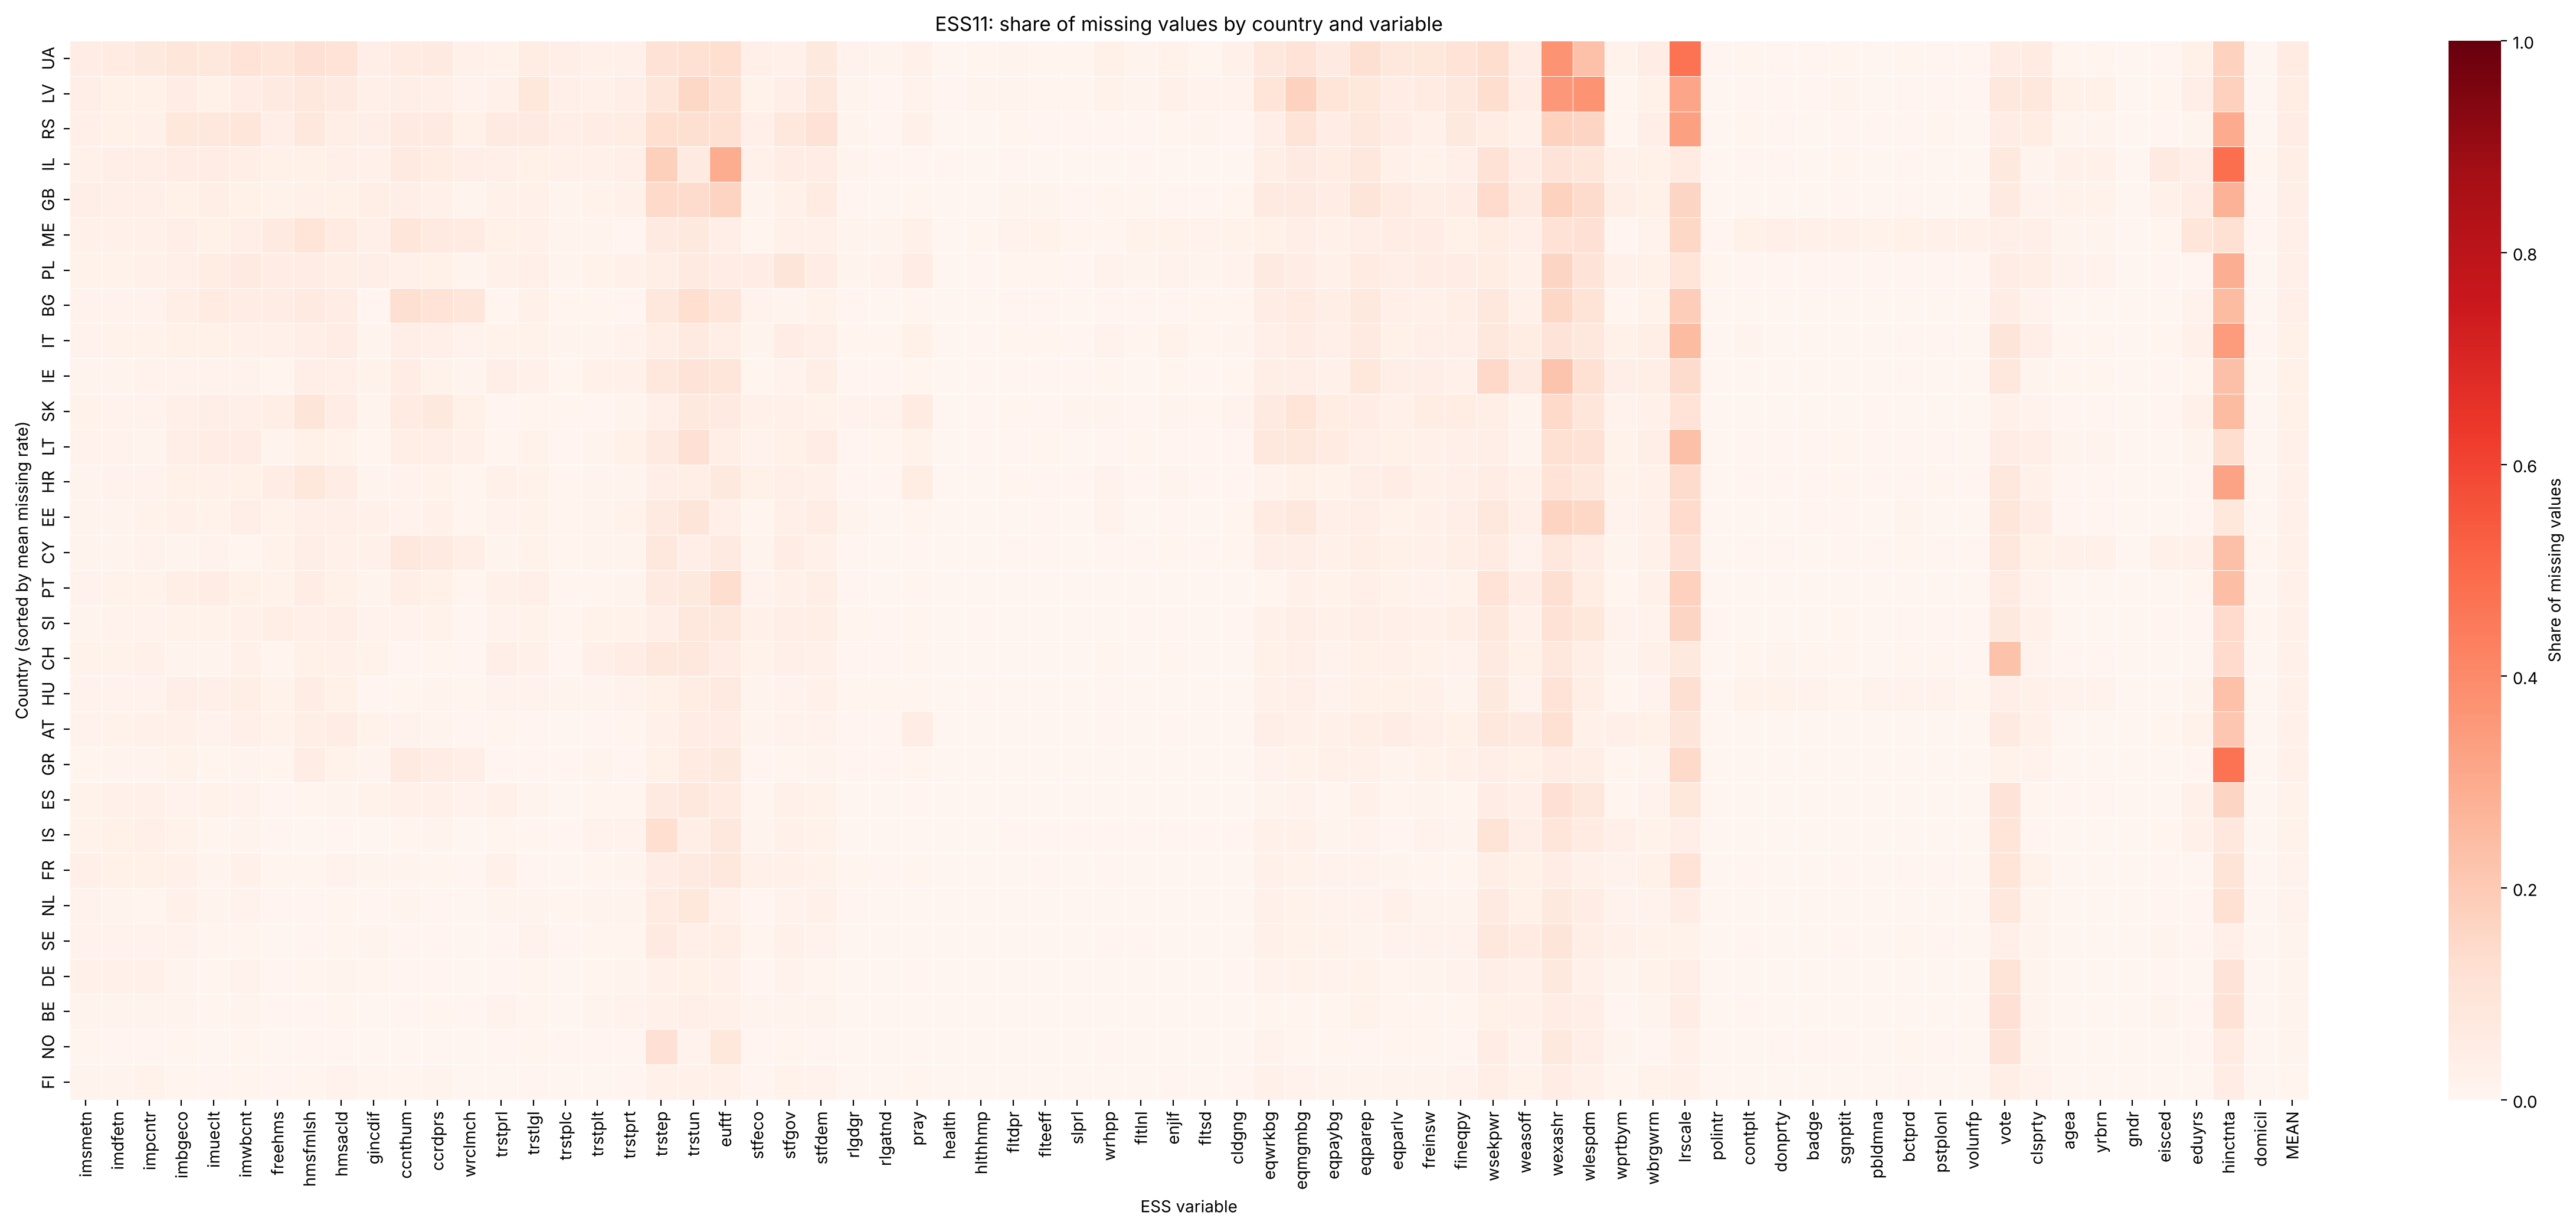

In [8]:
taux = donnees.taux_manquants_par_pays(df, list(donnees.VARIABLES) + list(donnees.SOCIODEMO))
taux.to_csv(donnees.DOSSIER_SORTIE / "taux_manquants_par_pays.csv")
donnees.heatmap_manquants(taux)
plt.show()

Taux moyen de valeurs manquantes par pays :

In [9]:
taux["MEAN"].round(3)

cntry
UA    0.06
LV    0.06
RS    0.05
IL    0.04
GB    0.04
ME    0.04
PL    0.04
BG    0.04
IT    0.04
IE    0.03
SK    0.03
LT    0.03
HR    0.03
EE    0.03
CY    0.03
PT    0.03
SI    0.03
CH    0.03
HU    0.03
AT    0.03
GR    0.02
ES    0.02
IS    0.02
FR    0.02
NL    0.02
SE    0.01
DE    0.01
BE    0.01
NO    0.01
FI    0.01
Name: MEAN, dtype: float64

### 1.5 Exclusion de pays et de variables après analyse de la heatmap

Après analyse de la heatmap, il apparaît que tous les pays affichent, pour la plupart des variables, des taux de réponse satisfaisants, à l'exception de l'Ukraine. On l'exclut.
De plus, `hinctnta` est aussi une question faiblement répondue dans une majorité de pays : on l'exclue

On exclut également Israël, puisque le choix a été fait de se concentrer sur les pays européens.

In [10]:
df = donnees.exclure_pays(df, donnees.PAYS_EXCLUS)
df = donnees.exclure_variables(df, donnees.VARIABLES_EXCLUES)

Pays exclus : ['UA', 'IL'] -> 3,567 répondants retirés, 46,549 restants
Variables exclues : ['hinctnta']


### 1.6 Recodage, normalisation, renommage

In [11]:
df = donnees.recoder_et_normaliser(df)
df = donnees.nettoyer_sociodemo(df)

### 1.7 Variables politiques et indices thématiques

On crée de nouvelles variables afin de réaliser notre étude

- `lrscale` : positionnement gauche 0 / droite 10
- `lrscaleabs` = |lrscale − 5| : extrémité idéologique, de 0 (centre) à 5 (extrême) ;
- `politiscale` : indice de politisation sur [0, 1], moyenne de trois composantes :
  - intérêt pour la politique (`polintr`) 
  - participation : part des 8 actions politiques réalisées dans les 12 derniers mois 
  - lien partisan : a voté aux dernières élections, se sent proche d'un parti.

  L'indice est calculé si au moins 2 des 3 composantes sont disponibles.

Les indices thématiques `idx_<groupe>` sont la moyenne des items normalisés de chaque groupe, calculée si au moins la moitié des items sont renseignés.

In [12]:
df = donnees.creer_variables_politiques(df)
df = donnees.creer_indices_thematiques(df)

### 1.8 Enrichissement 1 : partis votés (PartyFacts + ParlGov)

On enrichit le dataset de deux autres bases de données, qui recense le positionnement politique des différents partis d'Europe (et leur alignement sur certains sujets): on peut donc utiliser le vote des répondants.

In [13]:
df = donnees.enrichir_partis(df)

Vote identifié pour 60.7% des répondants (33 variables prtv* trouvées)
[PartyFacts] Parti relié à ParlGov pour 69.5% des votants identifiés


### 1.9 Enrichissement 2 : données pays via l'API Eurostat
 Le second enrichissement est tiré de l'API Eurostat, qui donne des données supplémentaires sur chaque pays : 
 
- PIB par habitant en standard de pouvoir d'achat : `tec00114` ;
- coefficient de Gini du revenu disponible : `ilc_di12` ;
- taux de chômage des 15-74 ans : `une_rt_a`.

Eurostat ne couvre pas Israël et le Royaume-Uni depuis 2020, et seulement en partie les pays candidats : leurs valeurs resteront NaN.

In [14]:
df = donnees.enrichir_eurostat(df)

Dataset not found: tec00114
[Eurostat] pib_hab_spa (tec00114) non récupéré : 


Dataset not found: ilc_di12
[Eurostat] gini (ilc_di12) non récupéré : 


Dataset not found: une_rt_a
[Eurostat] taux_chomage (une_rt_a) non récupéré : 
[Eurostat] Pays sans données : ['AT', 'BE', 'BG', 'CH', 'CY', 'DE', 'EE', 'ES', 'FI', 'FR', 'GB', 'GR', 'HR', 'HU', 'IE', 'IS', 'IT', 'LT', 'LV', 'ME', 'NL', 'NO', 'PL', 'PT', 'RS', 'SE', 'SI', 'SK']


Le PIB par habitant et le taux de chômage sont fournis pour d'éventuelles analyses au niveau pays (La polarisation est-elle plus forte dans les pays plus inégalitaires ou en difficulté économique,etc ?) ; ils ne sont pas exploités dans les parties 2 et 3.

### 1.10 Pondérations

On pondère avec `anweight`, le poids d'analyse recommandé par l'ESS. Les fonctions de moyenne et de corrélation pondérées, utilisées dans les parties 2 et 3, sont dans `scripts/outils.py`.

### 1.11 Dictionnaire des variables et export

In [15]:
propre = df[donnees.selection_colonnes_finales(df)]
donnees.exporter(propre)
print(f"Base finale : {propre.shape[0]:,} répondants, {propre.shape[1]} variables")
propre.head()

Export : data/ess11_propre.csv
Base finale : 46,549 répondants, 102 variables


,idno,cntry,essround,anweight,pspwght,pweight,dweight,genre_resp,annee_naissance,age,lieu_vie,education_isced,annees_etudes,femme,tranche_age,...,idx_redistribution,idx_ecologie,idx_confiance_institutionnelle,idx_europe,idx_satisfaction,idx_religiosite,idx_genre,idx_sante,parti_ess_id,parti_partyfacts_id,parti_famille,parti_lr,parti_etat_marche,parti_liberte_autorite,parti_pro_ue
0,50014,AT,11,0.13,0.39,0.33,1.19,1,1958.0,65.0,3.0,3.0,12.0,0,60-74,...,0.75,0.63,0.64,0.6,0.53,0.33,0.56,0.88,AT-11-1-v,1384,Social democracy,3.73,3.47,3.48,8.45
1,50030,AT,11,0.11,0.33,0.33,0.61,2,2002.0,21.0,1.0,5.0,14.0,1,15-29,...,1.0,0.83,0.39,0.9,0.47,0.06,0.68,0.62,AT-11-5-v,1659,Green/Ecologist,2.46,2.75,1.43,6.68
2,50057,AT,11,1.32,4.00,0.33,1.39,2,1970.0,53.0,3.0,6.0,16.0,1,45-59,...,1.0,0.85,0.57,0.7,0.57,0.6,0.83,0.77,AT-11-5-v,1659,Green/Ecologist,2.46,2.75,1.43,6.68
3,50106,AT,11,0.06,0.18,0.33,0.56,2,1945.0,78.0,1.0,5.0,14.0,1,75+,...,1.0,0.7,0.49,0.5,0.47,0.48,0.72,0.58,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN
4,50145,AT,11,0.35,1.06,0.33,0.72,1,1959.0,64.0,4.0,3.0,12.0,0,60-74,...,0.75,0.92,0.66,1.0,0.7,0.03,0.81,0.91,AT-11-5-v,1659,Green/Ecologist,2.46,2.75,1.43,6.68


### 1.12 Statistiques descriptives de la base finale

Le tableau produit contient les pourcentages de réponses valides pour les principales variables de l'étude

In [16]:
donnees.stats_descriptives_pays(propre)

28 pays, 46,549 répondants


,Répondants,Position gauche-droite (%),Politisation (%),Parti voté relié à ParlGov (%)
Pays,,,,
Italie,2865.0,75.3,99.9,32.1
Grèce,2757.0,85.2,100.0,64.5
Allemagne,2420.0,95.7,100.0,62.1
Autriche,2354.0,90.5,100.0,62.2
Bulgarie,2239.0,81.0,100.0,0.0
Hongrie,2118.0,87.3,100.0,41.4
Irlande,2017.0,86.2,100.0,57.2
Espagne,1844.0,91.4,100.0,46.9
France,1771.0,88.8,100.0,17.3


On constate donc que : 
- La position gauche-droite `lrscale` est renseignée dans 87% des cas
- La variable de politisation est remplie systématiquement à 99.9 %
- En revanche, le taux de réponse pour le vote du parti est beaucoup plus faible : 42.1%

<a id="partie2"></a>
## Partie 2 — Polarisation politique et attitudes : une cartographie des corrélations

**Question.** La position politique des Européens est-elle liée à leurs opinions sur d'autres sujets (immigration, redistribution, mœurs, religion, climat, institutions, santé) ? Si oui, lesquels ?

Nous utilisons les deux mesures de polarisation créées en partie 1 :
- **la position** gauche-droite `lrscale`, de 0 (gauche) à 10 (droite) ;
- **l'extrémité** `lrscaleabs` $= |\text{lrscale} - 5|$, de 0 (centre) à 5 (très à gauche ou très à droite).

Nous reproduisons deux figures de référence :
- **DellaPosta, Shi et Macy (2015), figure 1 :** les opinions sont-elles toutes un peu corrélées entre elles ?
- **Baldassarri et Gelman (2008), figure 2 :** quels sujets sont les plus liés à la position politique ?

Les fonctions de cette partie sont dans `scripts/correlations.py`.

### 2.1 Les données et la polarisation par pays

On part de la base nettoyée de la partie 1 (28 pays européens). On étudie les **49 questions d'opinion** que la partie 1 a regroupées en **10 domaines**. Comme en partie 1, on écarte une question sur le genre (« les femmes ont un meilleur sens moral »), qui n'est pas corrélée aux autres. Chaque question est notée de 0 à 1, une valeur haute voulant dire que l'énoncé est vrai : par exemple, pour « Same-sex couples may adopt », 1 = tout à fait d'accord.

In [17]:
df = correlations.charger_base()
items = correlations.liste_items(df)

tableau = correlations.tableau_pays(df)
tableau

46,549 répondants, 28 pays


,N,no_answer_lr_%,mean_position,mean_extremity
country,,,,
PL,1442,10.06,5.63,2.19
HU,2118,12.70,5.51,2.18
ME,1609,15.29,4.07,2.06
CY,685,11.82,5.20,1.91
SK,1442,11.23,4.77,1.88
SE,1230,2.20,4.93,1.87
NO,1337,2.47,5.15,1.84
FI,1563,3.01,5.46,1.80
BG,2239,18.98,5.38,1.79


**Figure 2** — Position gauche-droite et extrémité moyenne par pays.

Part au centre (5) : 31.6 %
Part aux extrêmes (0-1 ou 9-10) : 12.8 %


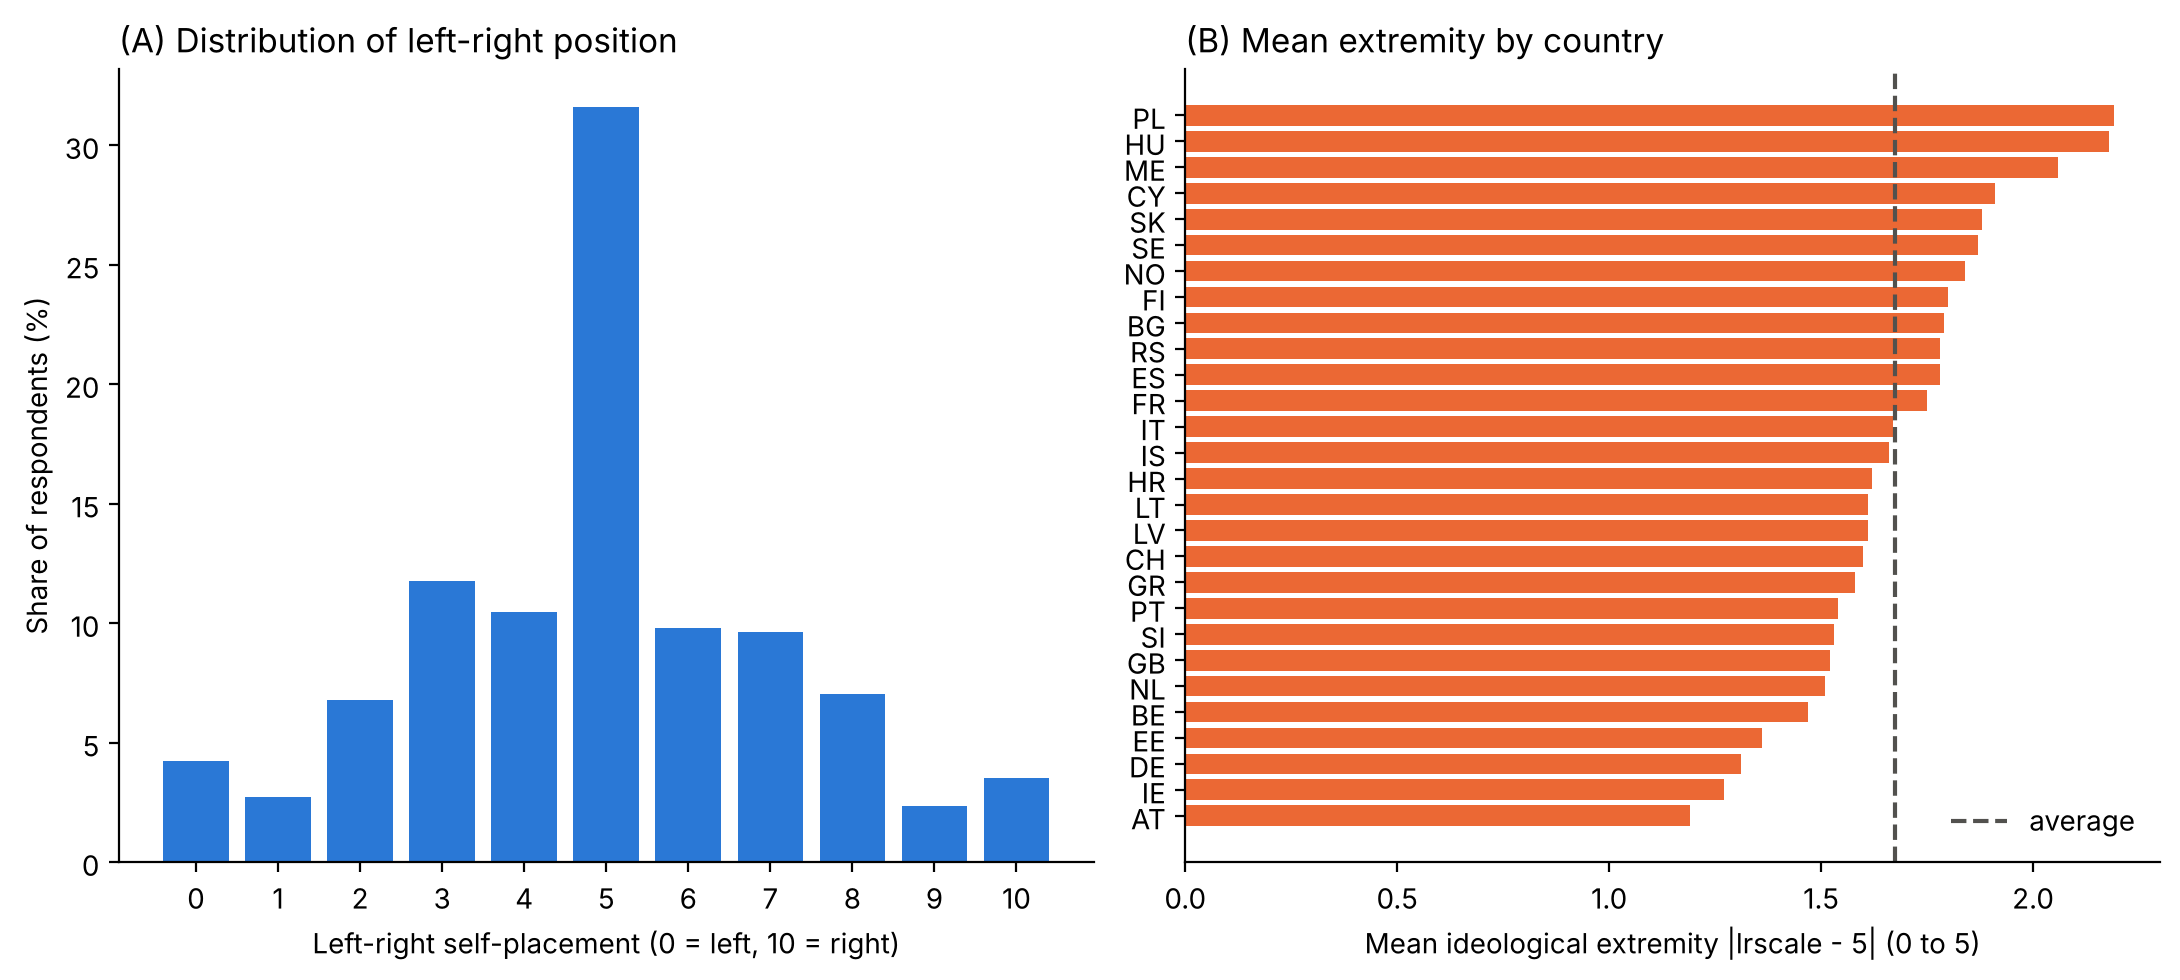

In [18]:
parts = correlations.figure_polarisation(df, tableau)
print(f"Part au centre (5) : {parts[5]:.1f} %")
print(f"Part aux extrêmes (0-1 ou 9-10) : {parts[[0, 1, 9, 10]].sum():.1f} %")

**À retenir.**
- **Un tiers des Européens (32 %) se placent exactement au centre.** Seuls 13 % se placent aux extrêmes.
- **La polarisation n'est pas réservée à l'Est.** La Pologne et la Hongrie sont les plus polarisées, mais la Suède, la Norvège et la Finlande sont aussi au-dessus de la moyenne. L'Autriche, l'Irlande et l'Allemagne sont les moins polarisées.
- **Une limite :** beaucoup de personnes ne se placent pas sur l'échelle en Serbie et en Lettonie (plus de 30 %, contre moins de 3 % en Suède). Dans ces pays, nos résultats portent sur les répondants les plus politisés.

### 2.2 Méthode

- **Corrélation de Pearson pondérée** par le poids d'analyse de l'ESS (`anweight`). Pour deux variables, on garde les personnes qui ont répondu aux deux questions. La seule exception est la figure 2 : comme elle décrit « les Européens », chaque pays y pèse selon sa population.
- **Pays par pays, puis moyenne simple sur les 28 pays.** Si on mélangeait tous les pays, on mesurerait aussi des différences *entre* pays (certains pays sont à la fois plus à droite et plus religieux que d'autres), alors qu'on veut des liens *entre personnes*. La section 2.4 montre que cela change vraiment les résultats.
- **Corrélations partielles** : comme DellaPosta et al., on vérifie que les liens ne viennent pas seulement de la démographie. Dans chaque pays, on retire de chaque variable ce qu'expliquent l'âge, le sexe, le diplôme et le fait de vivre en ville (régression linéaire simple, non pondérée), puis on corrèle ce qui reste avec la corrélation pondérée.

### 2.3 Les opinions sont-elles toutes corrélées entre elles ? (figure 1 de DellaPosta et al.)

On calcule la corrélation entre chaque paire de questions, soit 1 176 paires. Le calcul prend environ une minute (figure 3).

Corrélation moyenne |r| : 0.12  (partielle : 0.11)
Même domaine : 0.32  |  domaines différents : 0.09


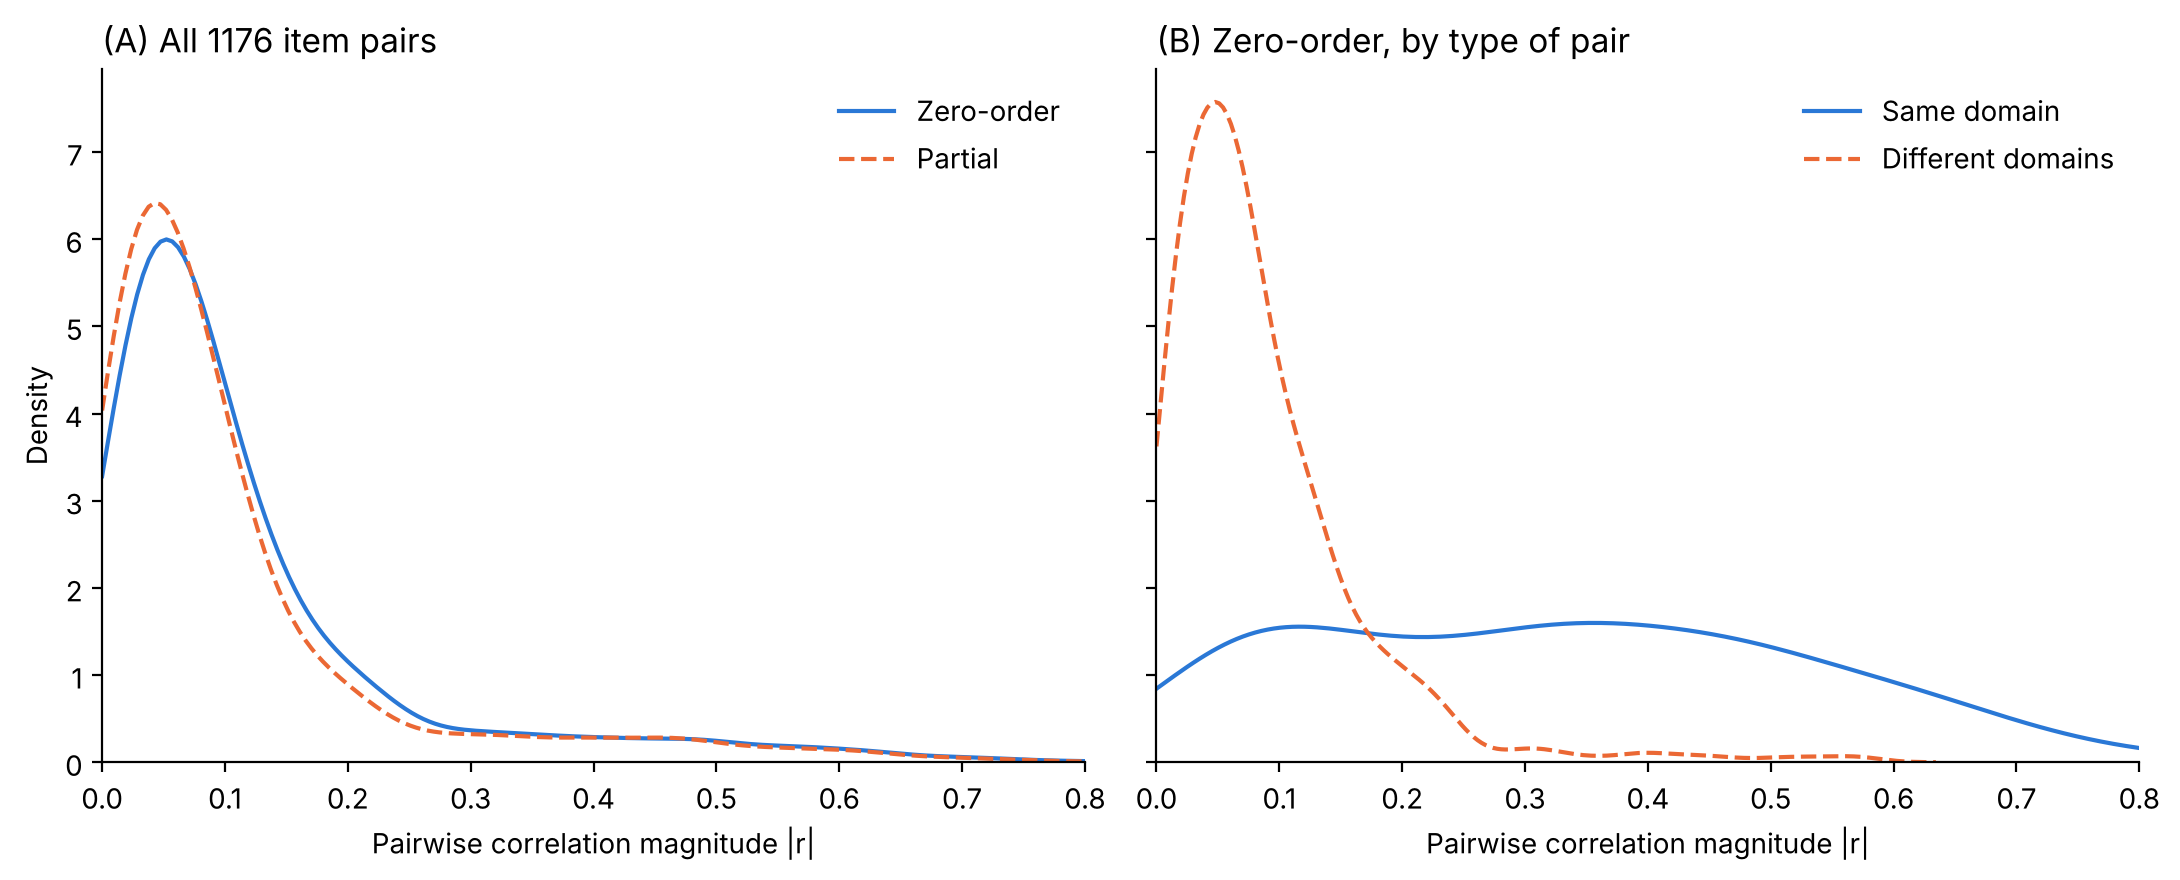

In [19]:
residus = correlations.residus_controles(df, items)
paires = correlations.table_paires(df, residus, items)
correlations.figure_dellaposta(paires)

print(f"Corrélation moyenne |r| : {paires['r'].abs().mean():.2f}  (partielle : {paires['r_partial'].abs().mean():.2f})")
print(f"Même domaine : {paires[paires['same_group']]['r'].abs().mean():.2f}  |  "
      f"domaines différents : {paires[~paires['same_group']]['r'].abs().mean():.2f}")

**À retenir.**
- **Comme dans la figure de DellaPosta et al., la plupart des corrélations sont faibles mais rarement nulles,** avec quelques liens forts. La moyenne est de 0,12, du même ordre que sur les données américaines de l'article (environ 0,09).
- **Contrôler la démographie ne change presque rien** (de 0,12 à 0,11) : les opinions ne vont pas ensemble simplement parce qu'elles dépendent de l'âge ou du diplôme.
- **Les liens forts sont surtout entre questions d'un même domaine** (0,32, contre 0,09 entre domaines). Mais certains domaines différents sont nettement liés, comme le montre le tableau ci-dessous.

In [20]:
# paires de domaines différents, sans les paires satisfaction x confiance
# (très corrélées, jusqu'à 0,57, mais elles mesurent la même chose : le soutien au système politique)
soutien = ["Satisfaction", "Institutional trust"]
garder = ~paires["same_group"] & ~(paires["group_1"].isin(soutien) & paires["group_2"].isin(soutien))
entre_domaines = paires[garder].copy()
entre_domaines["abs_r"] = entre_domaines["r"].abs()
entre_domaines.sort_values("abs_r", ascending=False).head(12)[["item_1", "item_2", "r", "r_partial"]]

,item_1,item_2,r,r_partial
911,EU unification should go further,Trust in the European Parliament,0.38,0.37
162,Immigration good for the economy,EU unification should go further,0.32,0.30
206,Immigrants enrich cultural life,EU unification should go further,0.31,0.29
249,Immigrants make country a better place,EU unification should go further,0.31,0.29
912,EU unification should go further,Trust in the United Nations,0.30,0.29
261,Immigrants make country a better place,Trust in the European Parliament,0.29,0.27
218,Immigrants enrich cultural life,Trust in the European Parliament,0.28,0.26
174,Immigration good for the economy,Trust in the European Parliament,0.28,0.26
262,Immigrants make country a better place,Trust in the United Nations,0.25,0.23
55,Allow immigrants of different ethnicity,Same-sex couples may adopt,0.25,0.20


**Les « lattes » européens.** Deux paquets d'opinions ressortent :
- **l'immigration, l'Europe et la confiance dans les institutions internationales vont ensemble.** Être favorable à l'immigration va de pair avec le soutien à l'intégration européenne et la confiance dans le Parlement européen ou l'ONU ;
- **l'immigration et les droits LGBT vont aussi ensemble.** Ce sont deux sujets sans lien logique, mais les personnes ouvertes sur l'un le sont souvent sur l'autre. C'est exactement l'idée de DellaPosta et al.

### 2.4 Les sujets liés à la gauche et à la droite sont-ils les mêmes partout ?

On calcule maintenant la corrélation de chaque question avec la **position gauche-droite**, dans chaque pays (figure 4). **Bleu** = opinion plus fréquente à gauche, **rouge** = plus fréquente à droite. La colonne `EUROPE` est la moyenne des pays.

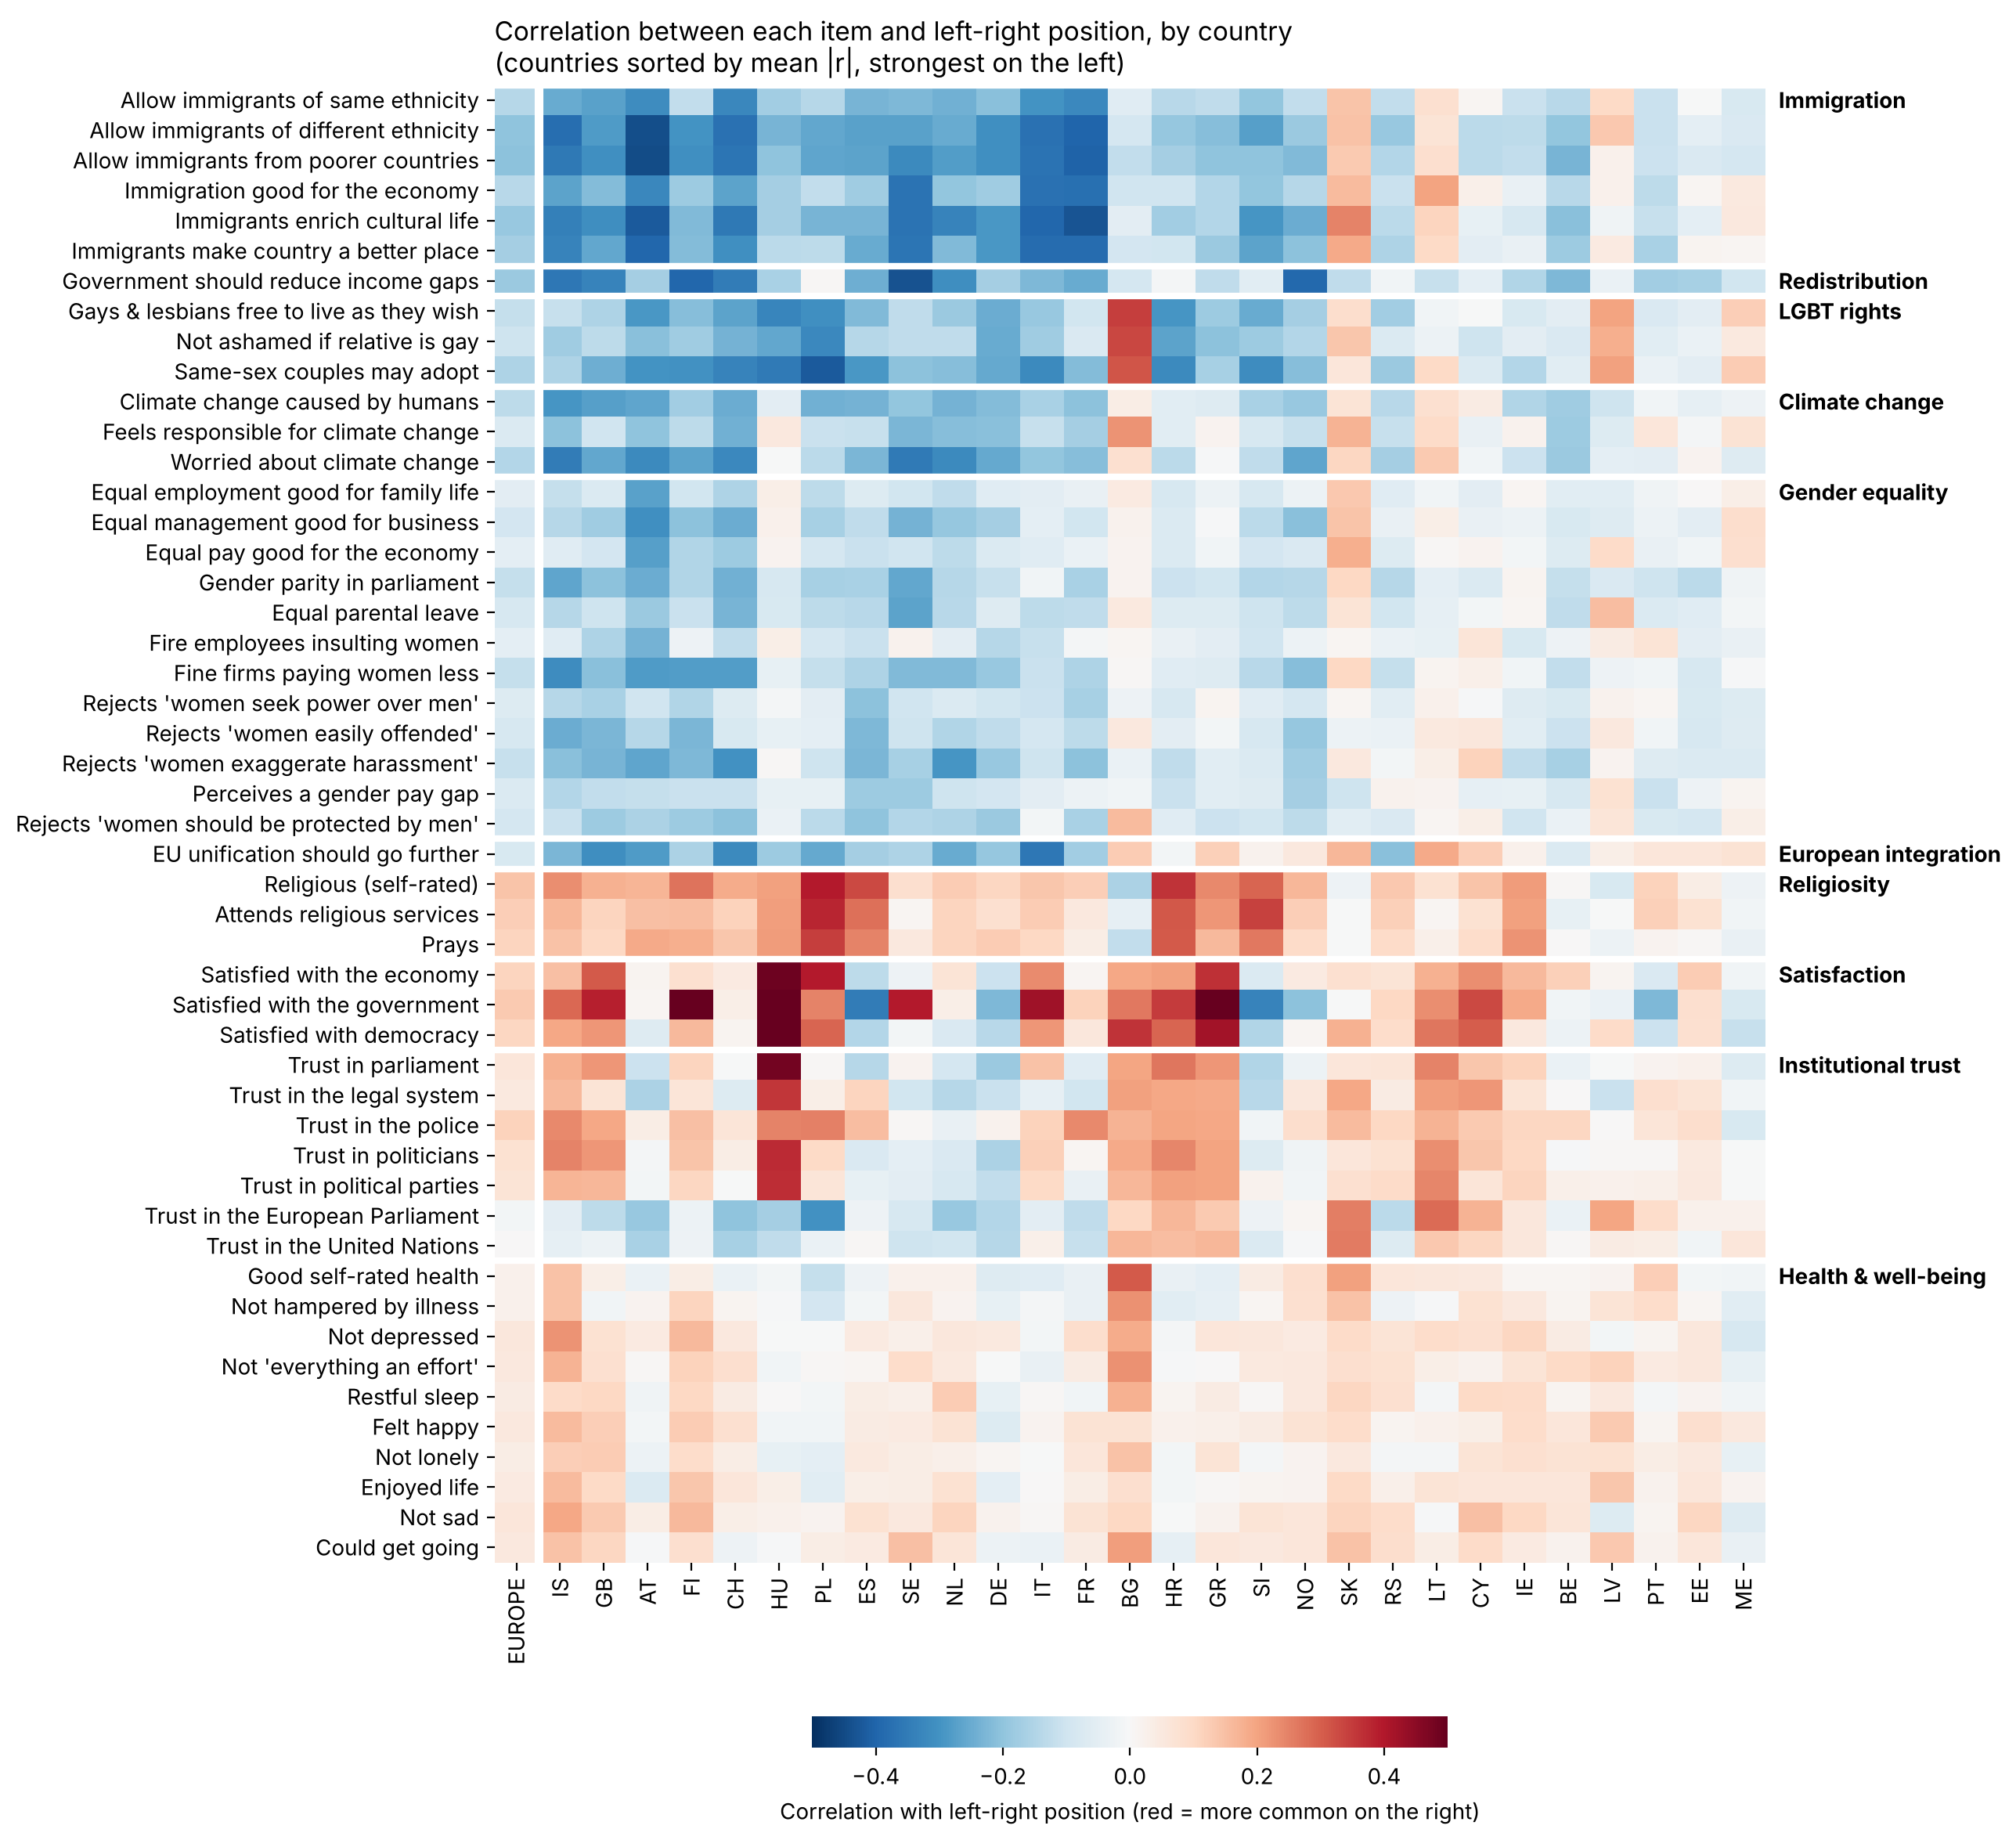

In [21]:
table_pays_lr = correlations.table_position_pays(df, items)
correlations.figure_heatmap(table_pays_lr, items)

**À retenir.**
- **En moyenne,** les opinions favorables à l'immigration, à la redistribution, aux droits LGBT et à la lutte contre le changement climatique sont plus fréquentes à gauche. La religiosité, la satisfaction et la confiance dans la police sont plus fréquentes à droite. La santé n'est presque pas liée à la position politique.
- **L'opposition gauche-droite est très marquée** en Islande, au Royaume-Uni, en Autriche, en Finlande et en Suisse. Elle est **presque absente** en Estonie, au Monténégro, au Portugal et en Lettonie.
- **Dans plusieurs pays de l'Est, les couleurs s'inversent** (Bulgarie, Lettonie, Lituanie, Slovaquie). En Bulgarie, par exemple, l'adoption par les couples de même sexe est plus soutenue à droite. Une explication possible : la « gauche » y désigne souvent les partis issus de l'ancien parti communiste, conservateurs sur les mœurs.
- **La satisfaction envers le gouvernement dépend de qui gouverne** (voir ci-dessous) : elle est liée à la droite là où la droite gouverne, et à la gauche là où la gauche gouverne.

Deux vérifications chiffrées :

In [22]:
# 1. Satisfaction envers le gouvernement : signe selon le pays
print(table_pays_lr.loc["Satisfied with the government"].sort_values().round(2).to_string())

# 2. Pays par pays ou tous pays mélangés ?
for item in ["europe_integration", "immig_culture"]:
    tous_pays = correlations.corr_ponderee(df[item], df["lrscale"], df[correlations.POIDS])
    pays_par_pays = table_pays_lr.loc[correlations.LIBELLES[item]].mean()
    print(f"{correlations.LIBELLES[item]} : tous pays mélangés {tous_pays:.2f}, pays par pays {pays_par_pays:.2f}")

cntry
ES   -0.35
SI   -0.33
DE   -0.22
PT   -0.22
NO   -0.21
ME   -0.08
LV   -0.03
BE   -0.02
SK   -0.00
AT    0.01
NL    0.03
CH    0.03
EE    0.08
RS    0.10
FR    0.11
IE    0.19
LT    0.23
PL    0.25
BG    0.26
IS    0.29
CY    0.33
HR    0.35
GB    0.39
SE    0.40
IT    0.42
GR    0.51
FI    0.56
HU    0.62
EU unification should go further : tous pays mélangés -0.20, pays par pays -0.08
Immigrants enrich cultural life : tous pays mélangés -0.29, pays par pays -0.19


- **Satisfaction envers le gouvernement.** La corrélation est positive en Hongrie, en Finlande, en Grèce et en Italie (gouvernements de droite au moment de l'enquête, 2023-2024), et négative en Espagne, en Slovénie, en Allemagne et au Portugal (gouvernements de gauche). C'est une opinion *partisane*, pas une opinion « de droite ».
- **Mélanger tous les pays surestime les liens :** -0,20 au lieu de -0,08 pour l'Europe, -0,29 au lieu de -0,19 pour l'immigration. D'où notre choix de calculer pays par pays.

### 2.5 Quels domaines sont liés à la position et à l'extrémité ? (figure 2 de Baldassarri et Gelman)

Pour chaque question, deux points (figure 5) :
- **en bleu, la corrélation avec la position gauche-droite.** Comme chez Baldassarri et Gelman, on retourne les questions pour que cette corrélation soit positive : *(rev.)* signifie qu'on lit la question à l'envers. Par exemple, « Same-sex couples may adopt (rev.) » se lit « être contre l'adoption ».
- **en orange, le lien entre l'extrémité et l'intensité de l'opinion.** L'intensité mesure à quel point la réponse s'éloigne de la moyenne du pays, dans un sens ou dans l'autre. Elle répond à la question : les personnes très à gauche ou très à droite ont-elles des opinions plus tranchées ?

    On ne corrèle pas directement l'extrémité avec l'opinion, parce qu'une personne très à gauche et une personne très à droite ont la même extrémité mais des opinions opposées : les deux s'annuleraient.

,r_position,r_extremity
group,,
Redistribution,0.19,0.07
Immigration,0.17,0.11
LGBT rights,0.13,0.07
Religiosity,0.13,0.04
Satisfaction,0.12,0.12
Climate change,0.12,0.07
Gender equality,0.08,0.04
European integration,0.08,0.13
Institutional trust,0.05,0.08


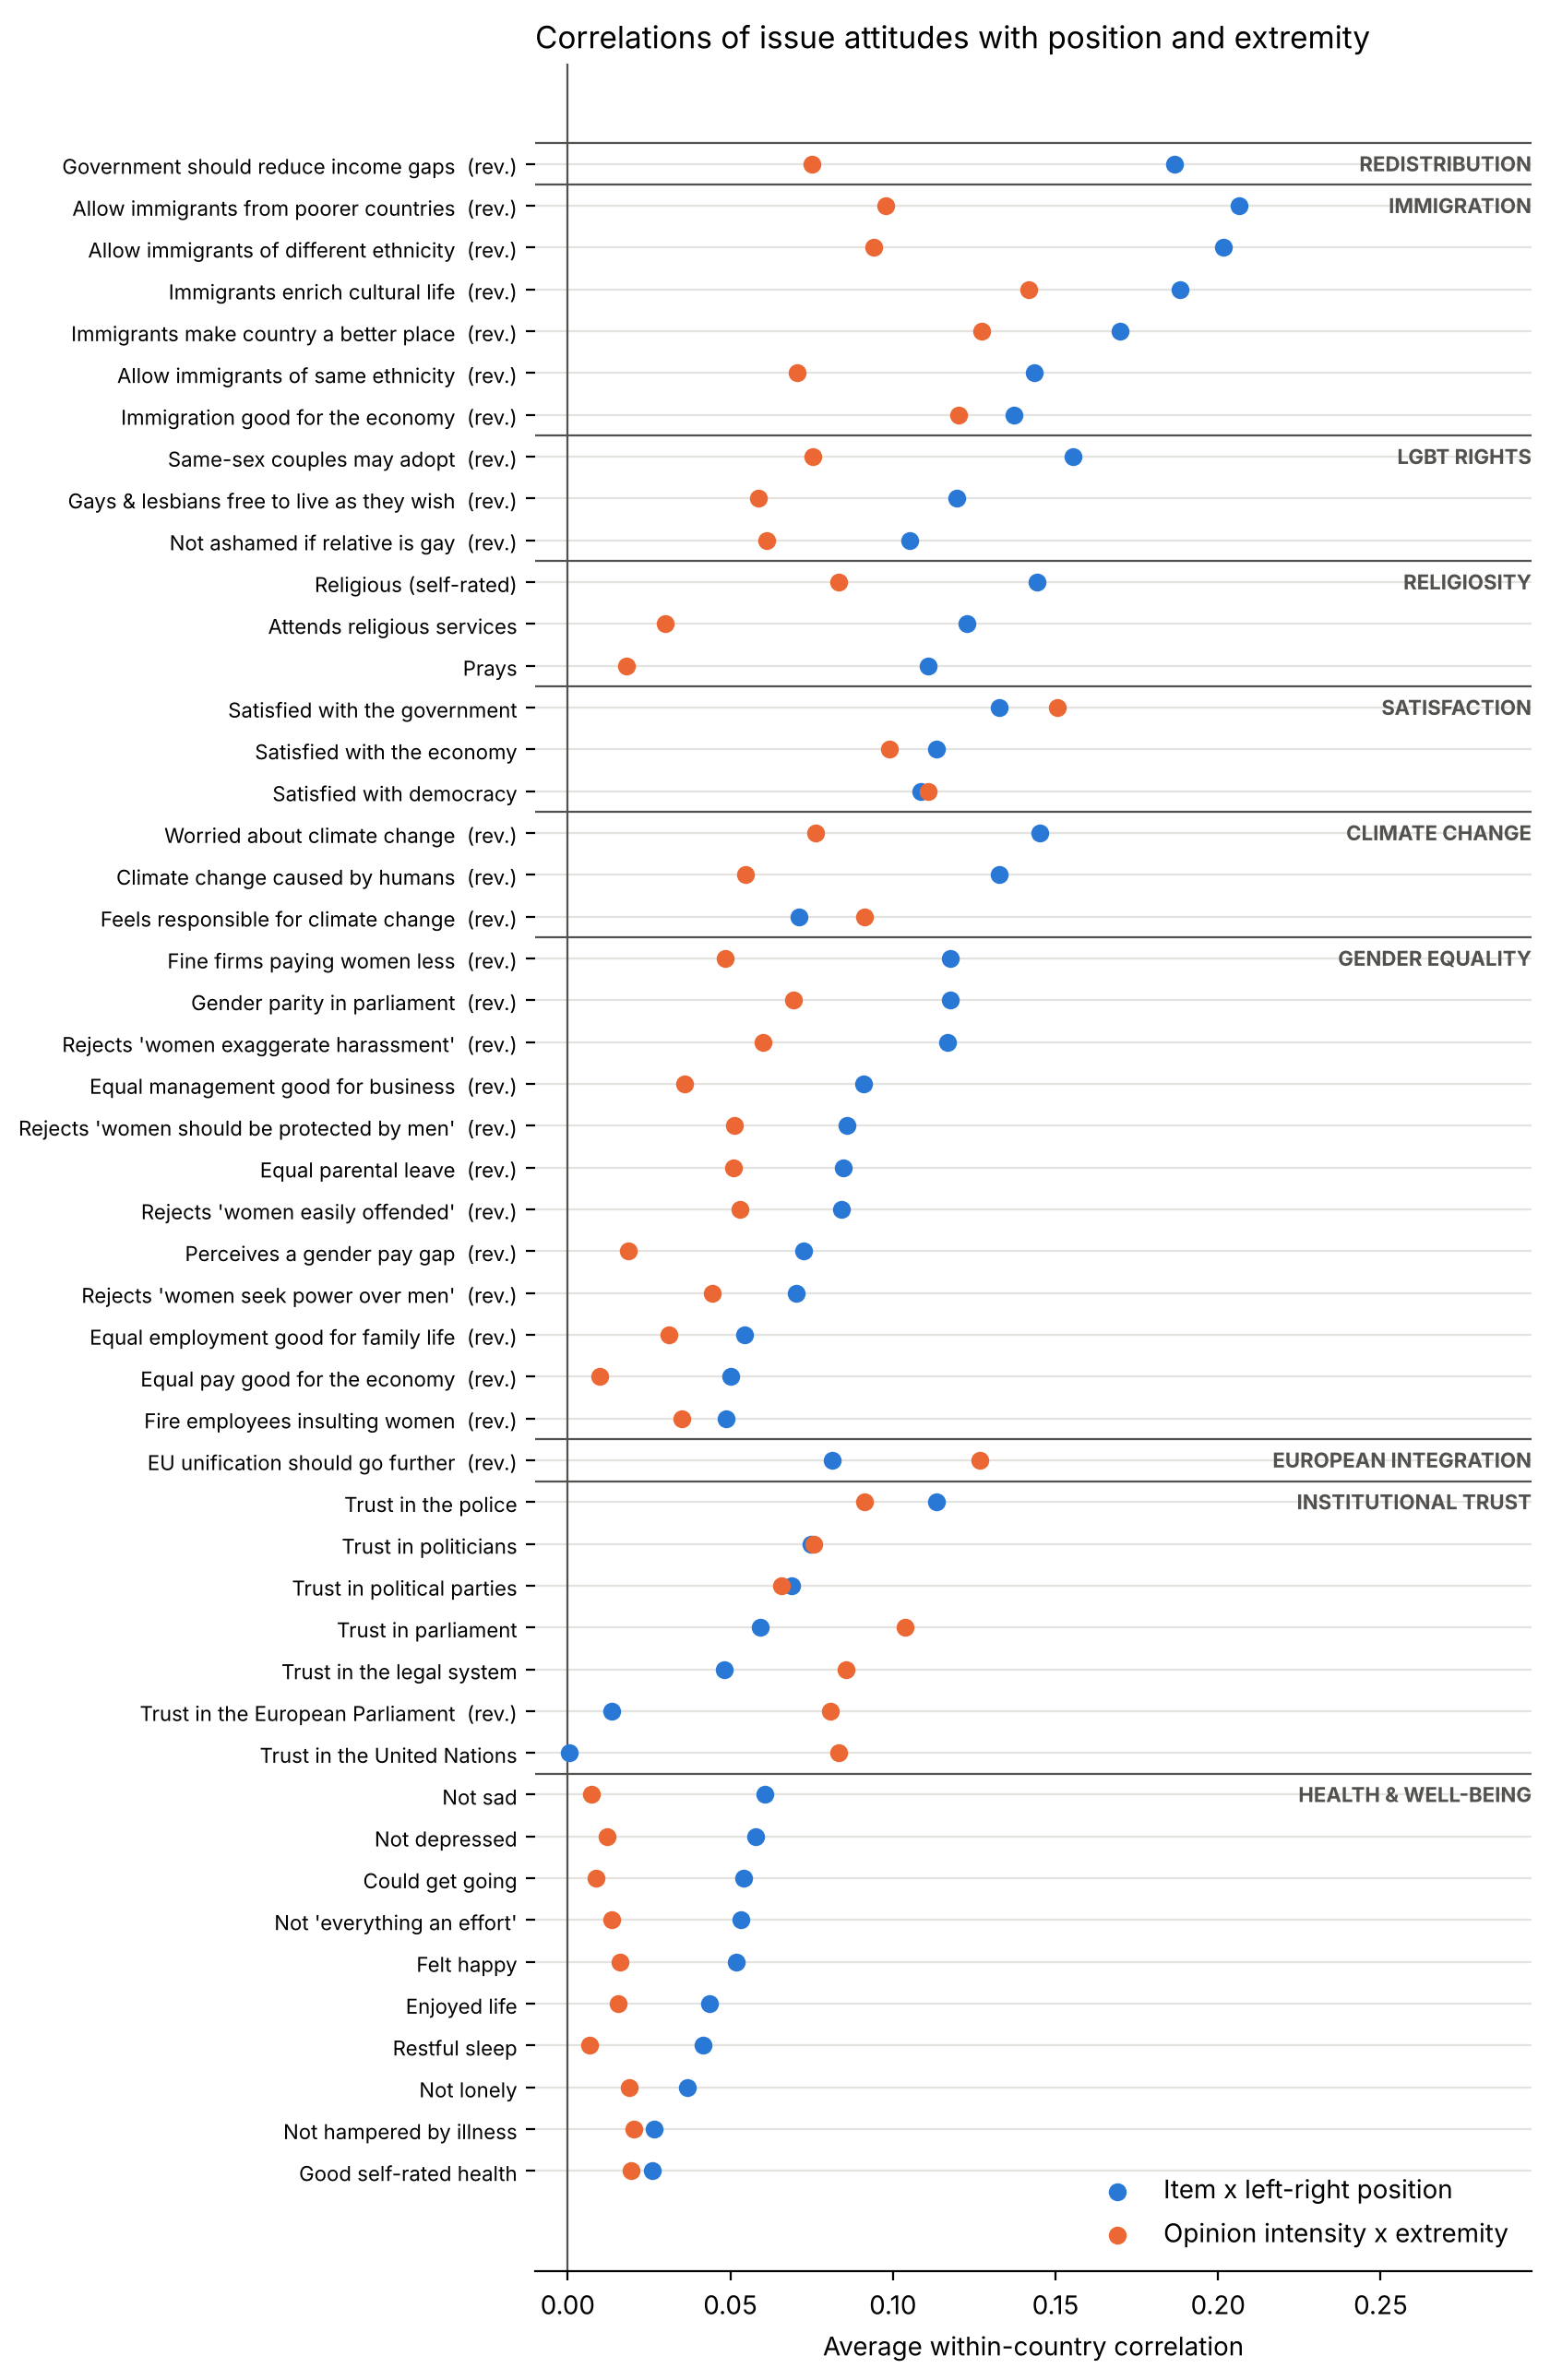

In [23]:
df_intensite = correlations.intensite(df, items)
table = correlations.table_bg(table_pays_lr, df_intensite, items)
correlations.figure_bg(table)

table.groupby("group")[["r_position", "r_extremity"]].mean().sort_values("r_position", ascending=False)

**À retenir.**
- **Points bleus : deux sujets dominent.** La **redistribution** (0,19) et **l'immigration** (0,17) sont les plus liées à la position gauche-droite. Viennent ensuite les droits LGBT, la religion, la satisfaction et le climat (environ 0,12), puis l'égalité femmes-hommes et l'Europe (0,08). La confiance dans les institutions et la santé ferment la marche (0,05).

    L'opposition gauche-droite européenne combine donc un axe **économique** (redistribution) et un axe **culturel** (immigration, mœurs, religion), comme chez Baldassarri et Gelman. Les corrélations sont toutefois plus faibles qu'aux États-Unis (au maximum 0,21 ici, contre environ 0,33 dans l'article).
- **Points orange : l'extrémité est surtout liée au rapport au système.** Les personnes aux extrêmes ont des opinions plus tranchées sur l'Europe (0,13), la satisfaction (0,12) et l'immigration (0,11). Sur l'Europe et la confiance dans les institutions, le point orange dépasse même le point bleu : ces sujets opposent davantage **le centre aux extrêmes** que la gauche à la droite.

### 2.6 Synthèse

1. **Les opinions des Européens sont faiblement mais systématiquement liées entre elles,** et la démographie ne l'explique pas. Comme chez DellaPosta et al., des sujets sans rapport logique (l'immigration et les droits LGBT) vont ensemble.
2. **La position gauche-droite est surtout liée à la redistribution et à l'immigration,** puis aux mœurs et à la religion. La santé n'y est presque pas liée.
3. **Ces liens varient beaucoup selon les pays.** Ils s'inversent dans plusieurs pays de l'Est.
4. **L'extrémité n'est pas la même chose que la position :** elle est liée au rejet ou à l'adhésion au système (Europe, institutions).

**Limites.**
- Une corrélation ne prouve pas une relation de cause à effet.
- L'ESS11 ne couvre qu'une seule année.
- La forte non-réponse à l'échelle gauche-droite dans certains pays.

**Vers la partie 3 :** les domaines les plus liés à la position politique (immigration, redistribution, mœurs) sont ceux dont la partie 3 étudie l'évolution selon l'âge.

<a id="partie3"></a>
## Partie 3 – Mécanisme théorique de l'alignement et dynamique par âge et par thème (ESS11)

Cette partie prolonge les Parties 1 et 2 à partir de la base nettoyée `data/ess11_propre.csv` (28 pays européens hors Ukraine, items normalisés sur $[0, 1]$ et structurés en 10 groupes thématiques) :

1. **Configuration et chargement** de `data/ess11_propre.csv`
2. **Simulation théorique (Baldassarri & Gelman, 2008, Fig. 1)** : comment la corrélation inter-enjeux génère une polarisation agrégée sans radicalisation individuelle
3. **Analyse empirique par âge et par groupe thématique (Kozlowski & Murphy, 2021, Fig. 1)** : estimation par B-splines cubiques sur ESS11
4. **Tests de robustesse et conclusion** : indices synthétiques `idx_<groupe>` et positionnement des partis votés `parti_lr` (ParlGov)

Les fonctions et paramètres de cette partie sont dans `scripts/alignement.py`.

### 3.1 Chargement de `ess11_propre.csv` et sous-échantillon analytique

In [24]:
pd.set_option("display.precision", 3)   # 3 décimales pour les tableaux de la partie 3

df_ess, weight_col, effectifs = alignement.charger_base_partie3(donnees.CHEMIN_PROPRE)
effectifs

Base Partie 1 : 46,549 répondants -> Sous-échantillon Partie 3 (âge & lrscale valides) : 40,114 (86.2%) | Pondération : anweight


,Effectif,Age_Moyen
age_bin_p3,,
15-24,3416,20.1
25-34,4844,29.9
35-44,6183,39.7
45-54,6820,49.7
55-64,7229,59.6
65-74,6799,69.3
75+,4823,80.4


### 3.2 Modèle théorique : polarisation par corrélation sans radicalisation (Baldassarri & Gelman, 2008)

On simule $K = 4$ dimensions d'opinion suivant $\mathbf{X}_i \sim \mathcal{N}_4(\mathbf{0}, \boldsymbol{\Sigma}_\rho)$ avec corrélation paire-à-paire uniforme $\rho \in [0, 1]$ :
* **Aucune radicalisation marginale :** chaque dimension conserve une distribution $\mathcal{N}(0, 1)$ quel que soit $\rho$.
* **Dispersion agrégée :** la variance du score moyen $\bar{X}_i = \frac{1}{4}\sum_{k=1}^4 X_{ik}$ vaut $\mathrm{Var}(\bar{X}_i) = \frac{1 + 3\rho}{4}$ et quadruple lorsque $\rho$ passe de $0$ à $1$, abaissant la densité au centre modéré au profit des extrémités(Panneau A) tout en rapprochant les individus d'un même camp et en éloignant les camps opposés en distance de Manhattan (Panneau B). C'est la figure 6.

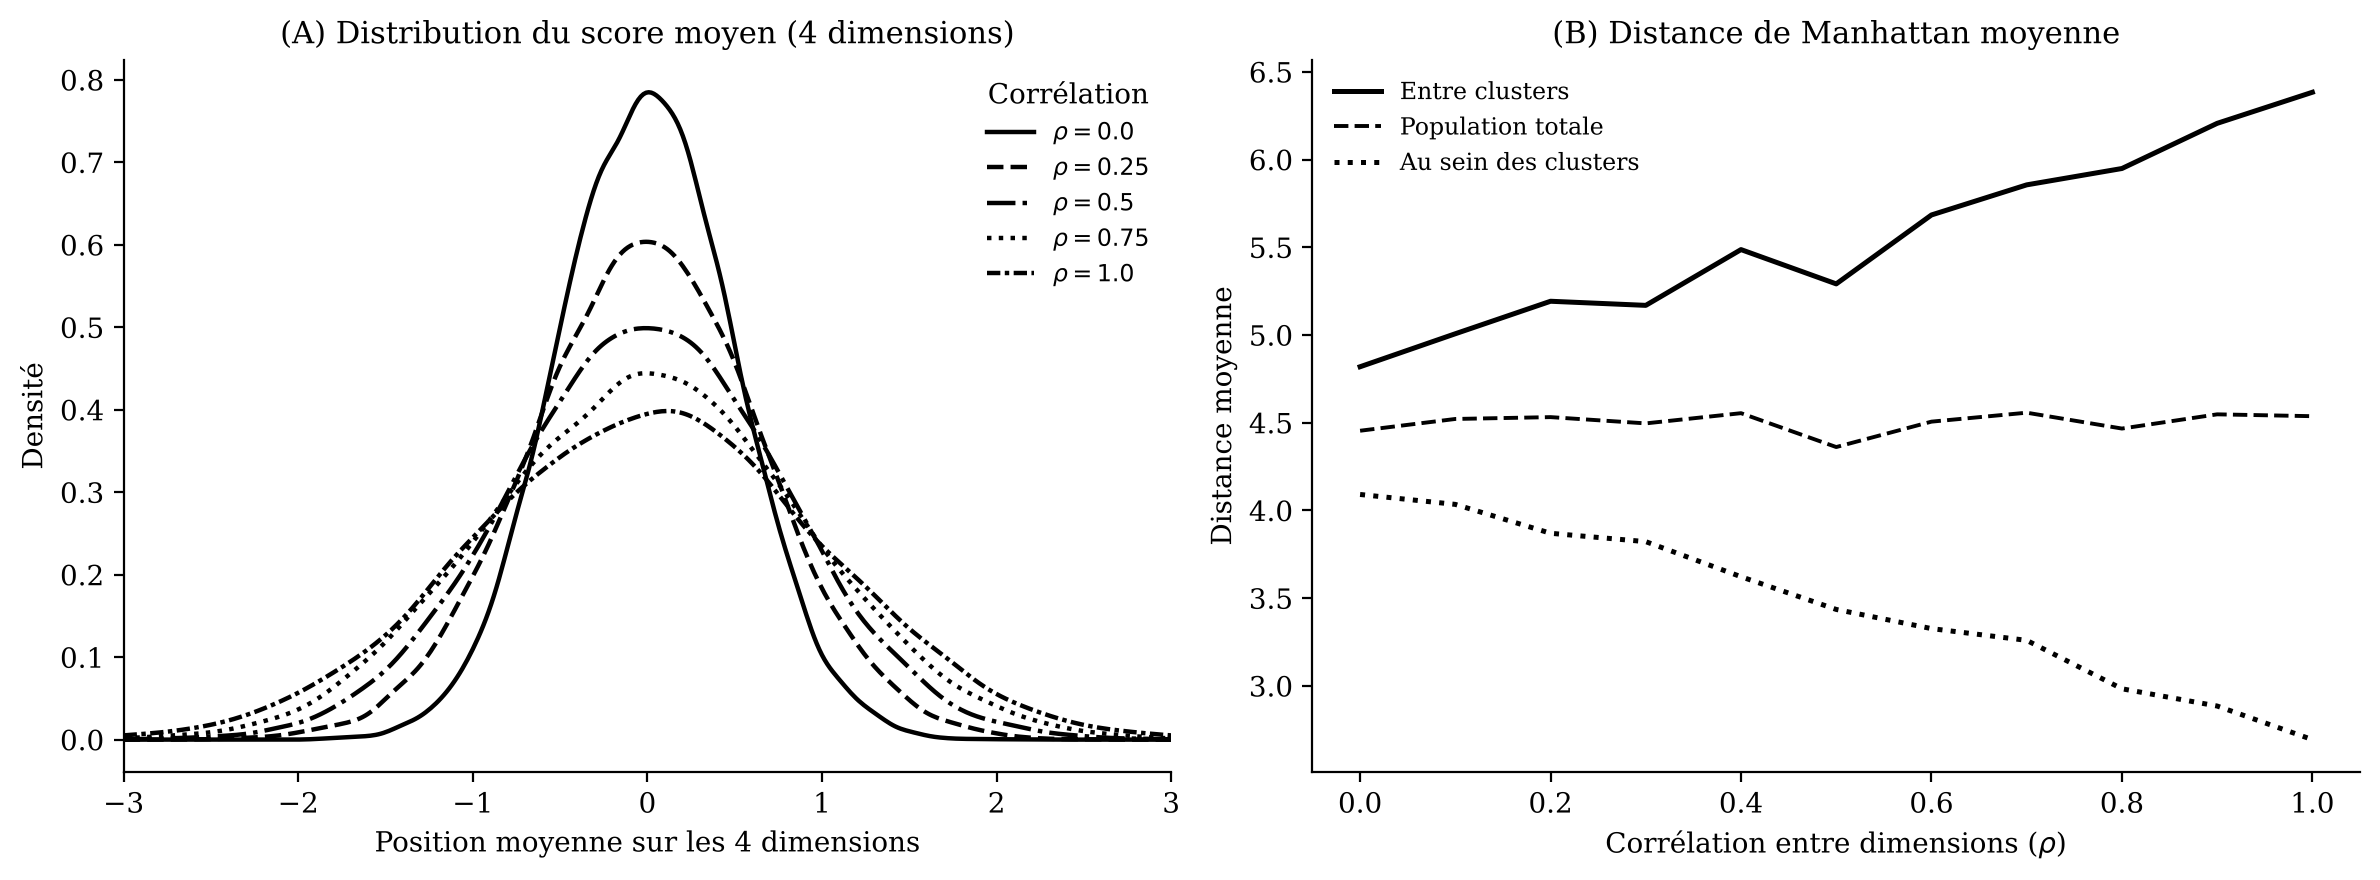

In [25]:
alignement.generate_bg_figure1()
plt.show()

#### Interprétation de la simulation (Baldassarri & Gelman, 2008)

Cette simulation illustre comment l'alignement entre différentes opinions peut accroître les écarts entre citoyens sans que leurs positions sur chaque sujet pris isolément ne deviennent plus extrêmes. Par construction, chacune des quatre dimensions d'opinion suit toujours la même loi normale centrée sur $0$ : les individus ne se radicalisent pas sur chaque question prise séparément.

En revanche, lorsque la corrélation $\rho$ entre les questions augmente :
* **Panneau (A) – Aplatissement de la distribution :** La distribution du score moyen $\bar{X}_i$ reste **en cloche (unimodale) et centrée sur $0$**, mais sa variance $\mathrm{Var}(\bar{X}_i) = \frac{1 + 3\rho}{4}$ est multipliée par quatre entre $\rho = 0$ et $\rho = 1$. Conformément aux conclusions de Baldassarri et Gelman (2008), la hausse de $\rho$ ne crée pas deux camps séparés, mais **aplatit et étire la distribution**, augmentant la proportion d'individus ayant des profils cohérents à gauche ou à droite.
* **Panneau (B) – Écartement entre camps :** La distance moyenne entre les individus situés à gauche ($\bar{X}_i < 0$) et ceux situés à droite ($\bar{X}_i \ge 0$) augmente nettement avec $\rho$, tandis que les individus d'un même camp deviennent plus proches les uns des autres.

### 3.3 Alignement idéologique par groupe thématique selon l'âge (Kozlowski & Murphy, 2021)

Pour chaque tranche d'âge décennale $a$ et chaque item $X_j$ du groupe thématique $g(j)$, on mesure l'intensité de la contrainte idéologique par la corrélation pondérée en valeur absolue $|r_{j,a}| = |\mathrm{Corr}_{w}(X_j, \mathrm{lrscale} \mid \mathrm{age} \in a)|$, puis on lisse les trajectoires de chacun des **10 groupes de la Partie 1** par B-splines cubiques ($\mathrm{df} = 3$) avec intervalles de confiance à $95\%$ (figure 7). La corrélation pondérée est la même fonction que dans la partie 2 (`scripts/outils.py`), avec un minimum de 30 réponses.

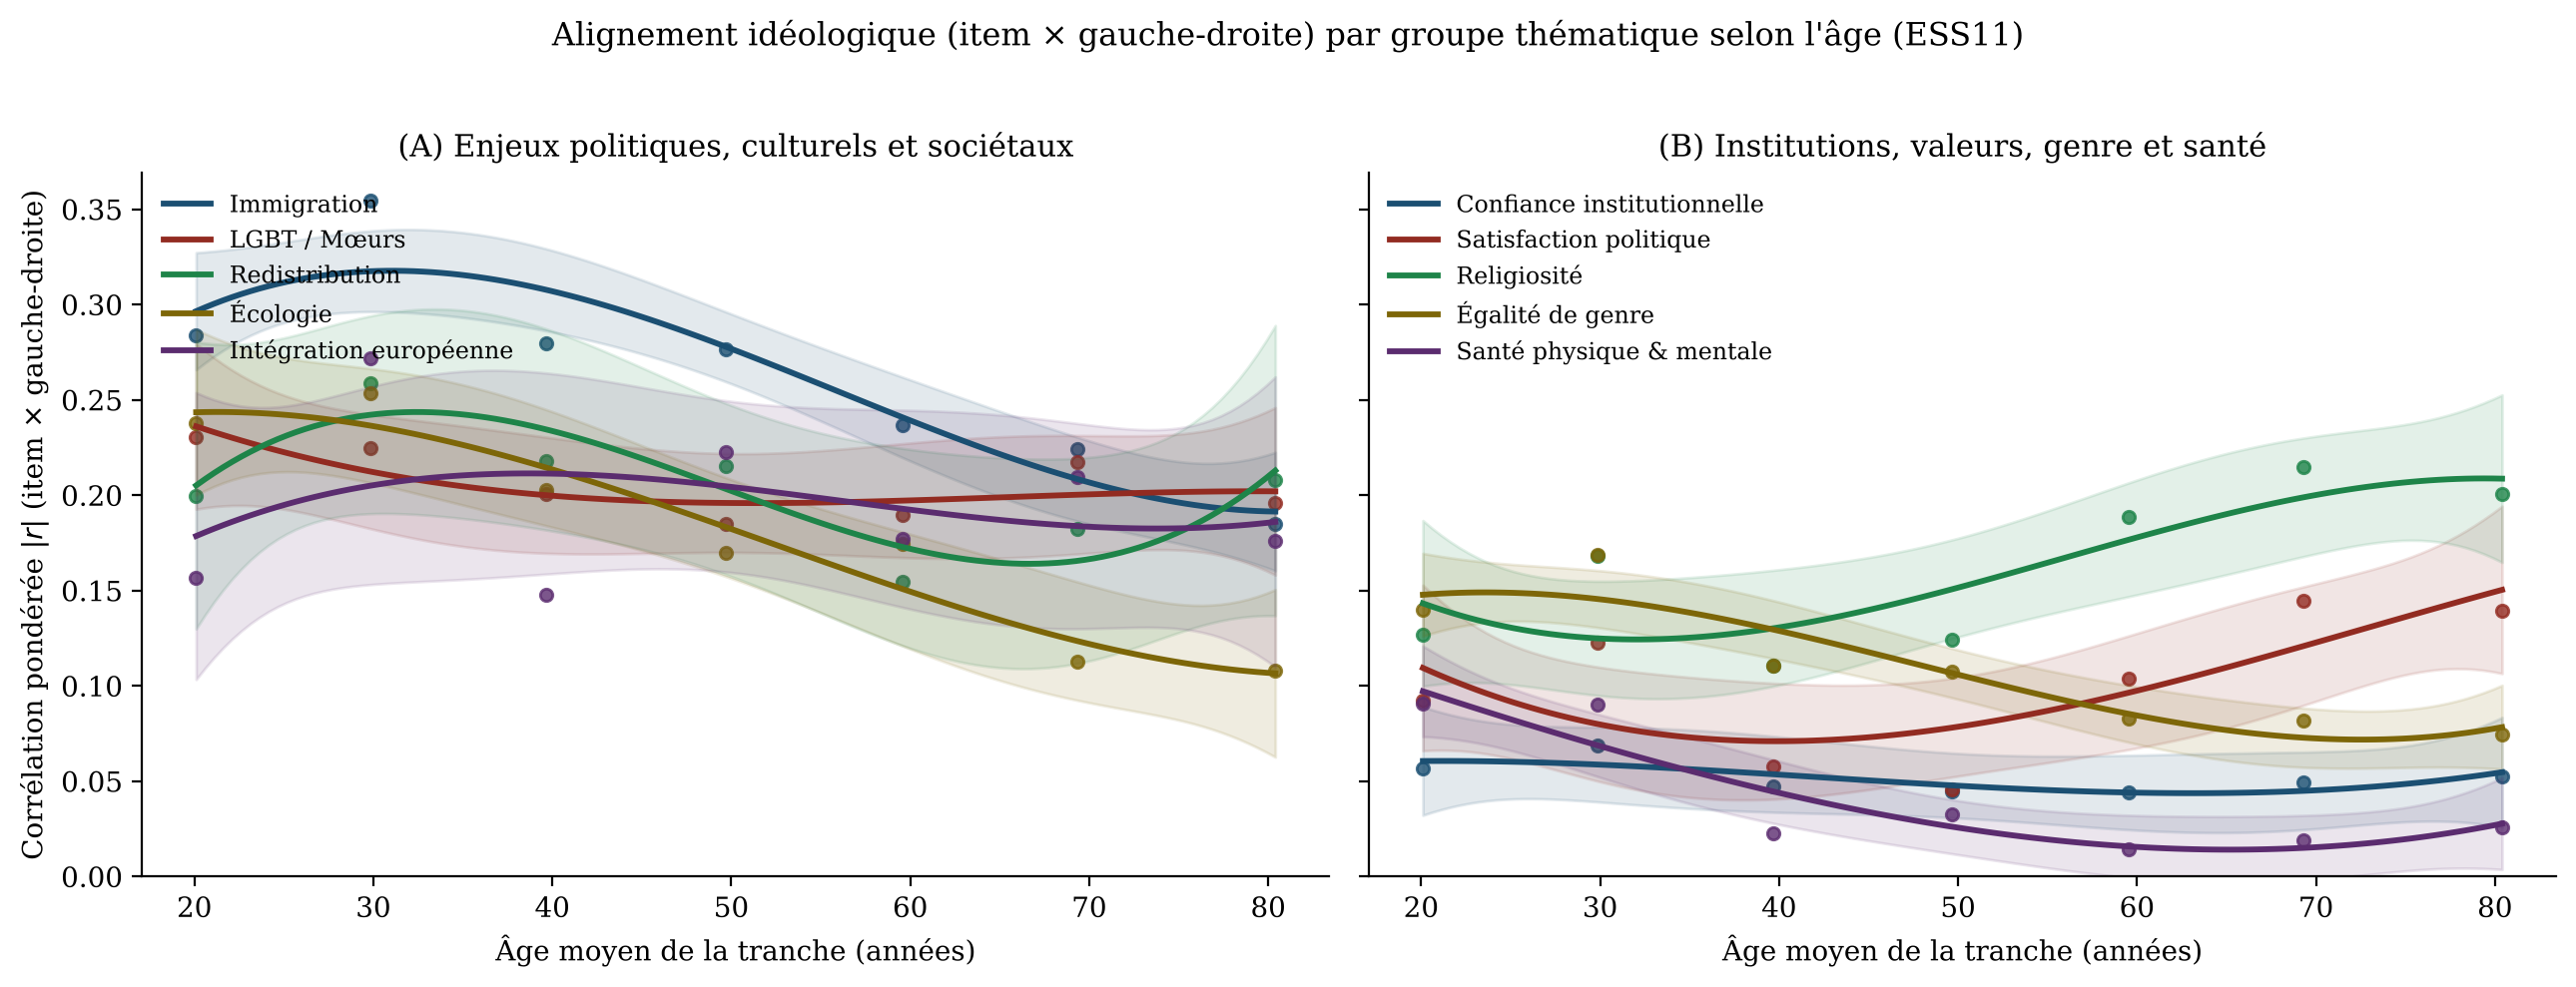

,Moyenne,Ecart_Type,Mediane,Max
label,,,,
Immigration,0.263,0.061,0.263,0.380
LGBT / Mœurs,0.206,0.046,0.197,0.282
Redistribution,0.205,0.032,0.208,0.259
Intégration européenne,0.195,0.043,0.177,0.272
Écologie,0.180,0.068,0.181,0.311
Religiosité,0.162,0.044,0.157,0.248
Égalité de genre,0.109,0.053,0.106,0.235
Satisfaction politique,0.101,0.043,0.107,0.170
Confiance institutionnelle,0.052,0.044,0.040,0.196


In [26]:
corr_main, summary_main = alignement.analyser_alignement_age_thematiques(
    df_ess, alignement.GROUPES_ITEMS, weight_col, target_col="lrscale",
    titre="Alignement idéologique (item × gauche-droite) par groupe thématique selon l'âge (ESS11)",
    ylabel=r"Corrélation pondérée $|r|$ (item $\times$ gauche-droite)",
    nom_png="fig07_kozlowski_ess11_age.png",
)
plt.show()
summary_main

#### Interprétation de l'alignement idéologique selon l'âge (figure 7)

Cette figure présente une **adaptation transversale** de la méthode de Kozlowski et Murphy (2021) sur les sept tranches d'âge d'ESS11 ($N = 40\,114$). Les courbes correspondent à un lissage par **polynômes de degré 3** des corrélations pondérées $|r_{j,a}|$ entre chaque question et l'auto-positionnement gauche-droite (`lrscale`), avec leurs intervalles de confiance à 95 %.

* **Hiérarchie thématique :** **L'immigration** ($|r| = \text{0,263}$) domine nettement le clivage gauche-droite, suivie d'un bloc serré réunissant les **enjeux LGBT / mœurs** ($\text{0,206}$), la **redistribution** ($\text{0,205}$) et **l'intégration européenne** ($\text{0,195}$), puis **l'écologie** ($\text{0,180}$) et la **religiosité** ($\text{0,162}$). La **santé physique et mentale** ($\text{0,042}$), retenue comme thème témoin, affiche une corrélation quasi nulle.
* **Effet de l'agrégation entre pays (cas de la confiance institutionnelle) :** Les corrélations sont ici calculées en regroupant tous les pays. Or, la **Partie 2** montre que ce choix gonfle certaines corrélations et en annule d'autres, comme la **confiance institutionnelle** ($\text{0,052}$ en agrégé), dont le signe s'inverse selon les contextes nationaux (par exemple, la confiance dans le parlement passe d'une corrélation agrégée quasi nulle à une moyenne pays par pays de $0,12$, atteignant $0,48$ en Hongrie).
* **Profils selon l'âge :** Contrairement à l'idée d'un sous-alignement généralisé des plus jeunes, l'alignement sur l'**immigration**, l'**écologie** et l'**égalité de genre** est maximal chez les jeunes adultes puis décroît avec l'âge. La baisse avec l'âge de l'alignement sur l'immigration se retrouve d'ailleurs en calculant pays par pays (de $0,23$ à $0,11$). Les enjeux **LGBT / mœurs**, la **redistribution** et l'**intégration européenne** restent globalement stables, tandis que seule la **religiosité** augmente nettement aux âges élevés.
* **Limite méthodologique :** L'enquête ESS11 étant transversale, ces profils reflètent des écarts entre cohortes présentes au moment de l'enquête, sans permettre d'isoler un effet propre au vieillissement.

### 3.4 Analyses de sensibilité et conclusion

Afin de vérifier que les trajectoires observées en Section 3 ne résultent pas d'artefacts de mesure propres aux questions isolées ou à l'auto-positionnement déclaré (`lrscale`), nous reconduisons l'estimation par B-splines à l'aide de deux variables construites en **Partie 1** :

1. **Indices thématiques synthétiques (`idx_<groupe>`) — validation interne (figure 8) :**
   * *Principe :* chaque indice agrège par moyenne les items normalisés d'un même domaine (par exemple les 6 questions sur l'immigration dans `idx_immigration` ou les 12 items sur l'égalité de genre dans `idx_genre`).
   * *Intérêt méthodologique :* cette agrégation neutralise le bruit aléatoire propre aux items isolés (*biais d'atténuation* qui tire les corrélations vers zéro) et accorde un poids strictement égal à chacun des 10 thèmes, indépendamment de son nombre initial de questions.
2. **Positionnement gauche-droite du parti voté (`parti_lr`, ParlGov) — validation externe (figure 9) :**
   * *Principe :* sur le sous-échantillon des électeurs dont le vote déclaré est rattaché à la base ParlGov ($N \ge 500$), on remplace l'auto-placement subjectif `lrscale` par le score gauche-droite attribué par des experts au parti choisi lors des dernières élections législatives.
   * *Intérêt méthodologique :* ce test limite les biais de subjectivité ou de rationalisation liés à l'auto-étiquetage politique et vérifie que l'alignement des attitudes par âge se traduit concrètement dans le **comportement électoral** effectif.

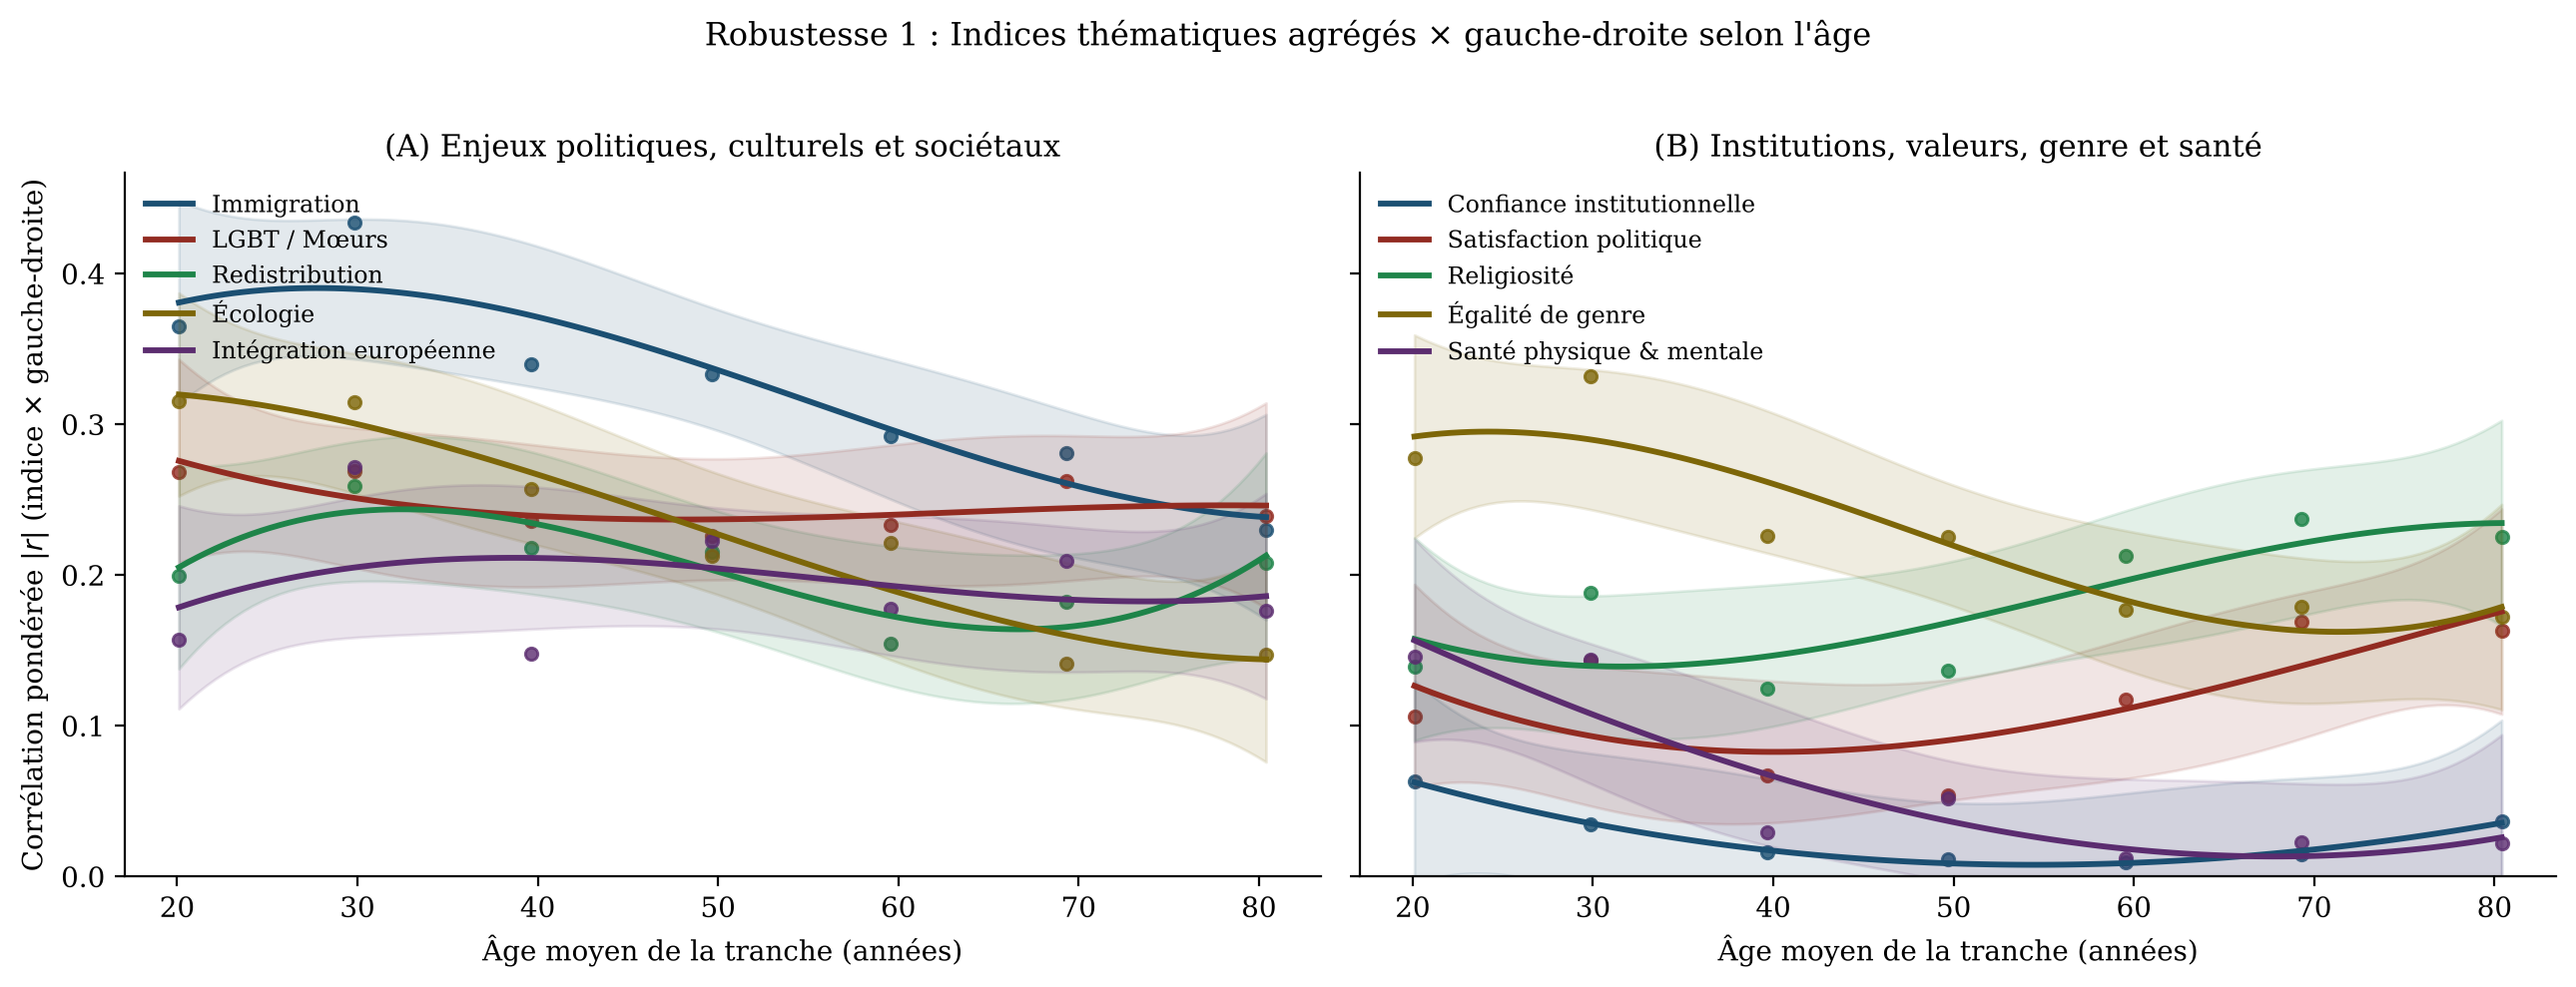

,Moyenne,Ecart_Type,Mediane,Max
label,,,,
Immigration,0.325,0.066,0.333,0.434
LGBT / Mœurs,0.248,0.018,0.239,0.269
Écologie,0.230,0.071,0.221,0.315
Égalité de genre,0.227,0.060,0.225,0.332
Redistribution,0.205,0.032,0.208,0.259
Intégration européenne,0.195,0.043,0.177,0.272
Religiosité,0.181,0.047,0.188,0.237
Satisfaction politique,0.117,0.045,0.117,0.169
Santé physique & mentale,0.061,0.058,0.030,0.146


In [27]:
# Robustesse 1 : Indices thématiques agrégés (idx_<groupe>)
GROUPES_INDICES = {g: [f"idx_{g}"] for g in alignement.GROUPES_ITEMS if f"idx_{g}" in df_ess.columns}
_, summary_idx = alignement.analyser_alignement_age_thematiques(
    df_ess, GROUPES_INDICES, weight_col, target_col="lrscale",
    titre="Robustesse 1 : Indices thématiques agrégés × gauche-droite selon l'âge",
    ylabel=r"Corrélation pondérée $|r|$ (indice $\times$ gauche-droite)",
    nom_png="fig08_robustesse_indices_thematiques.png",
)
plt.show()
summary_idx

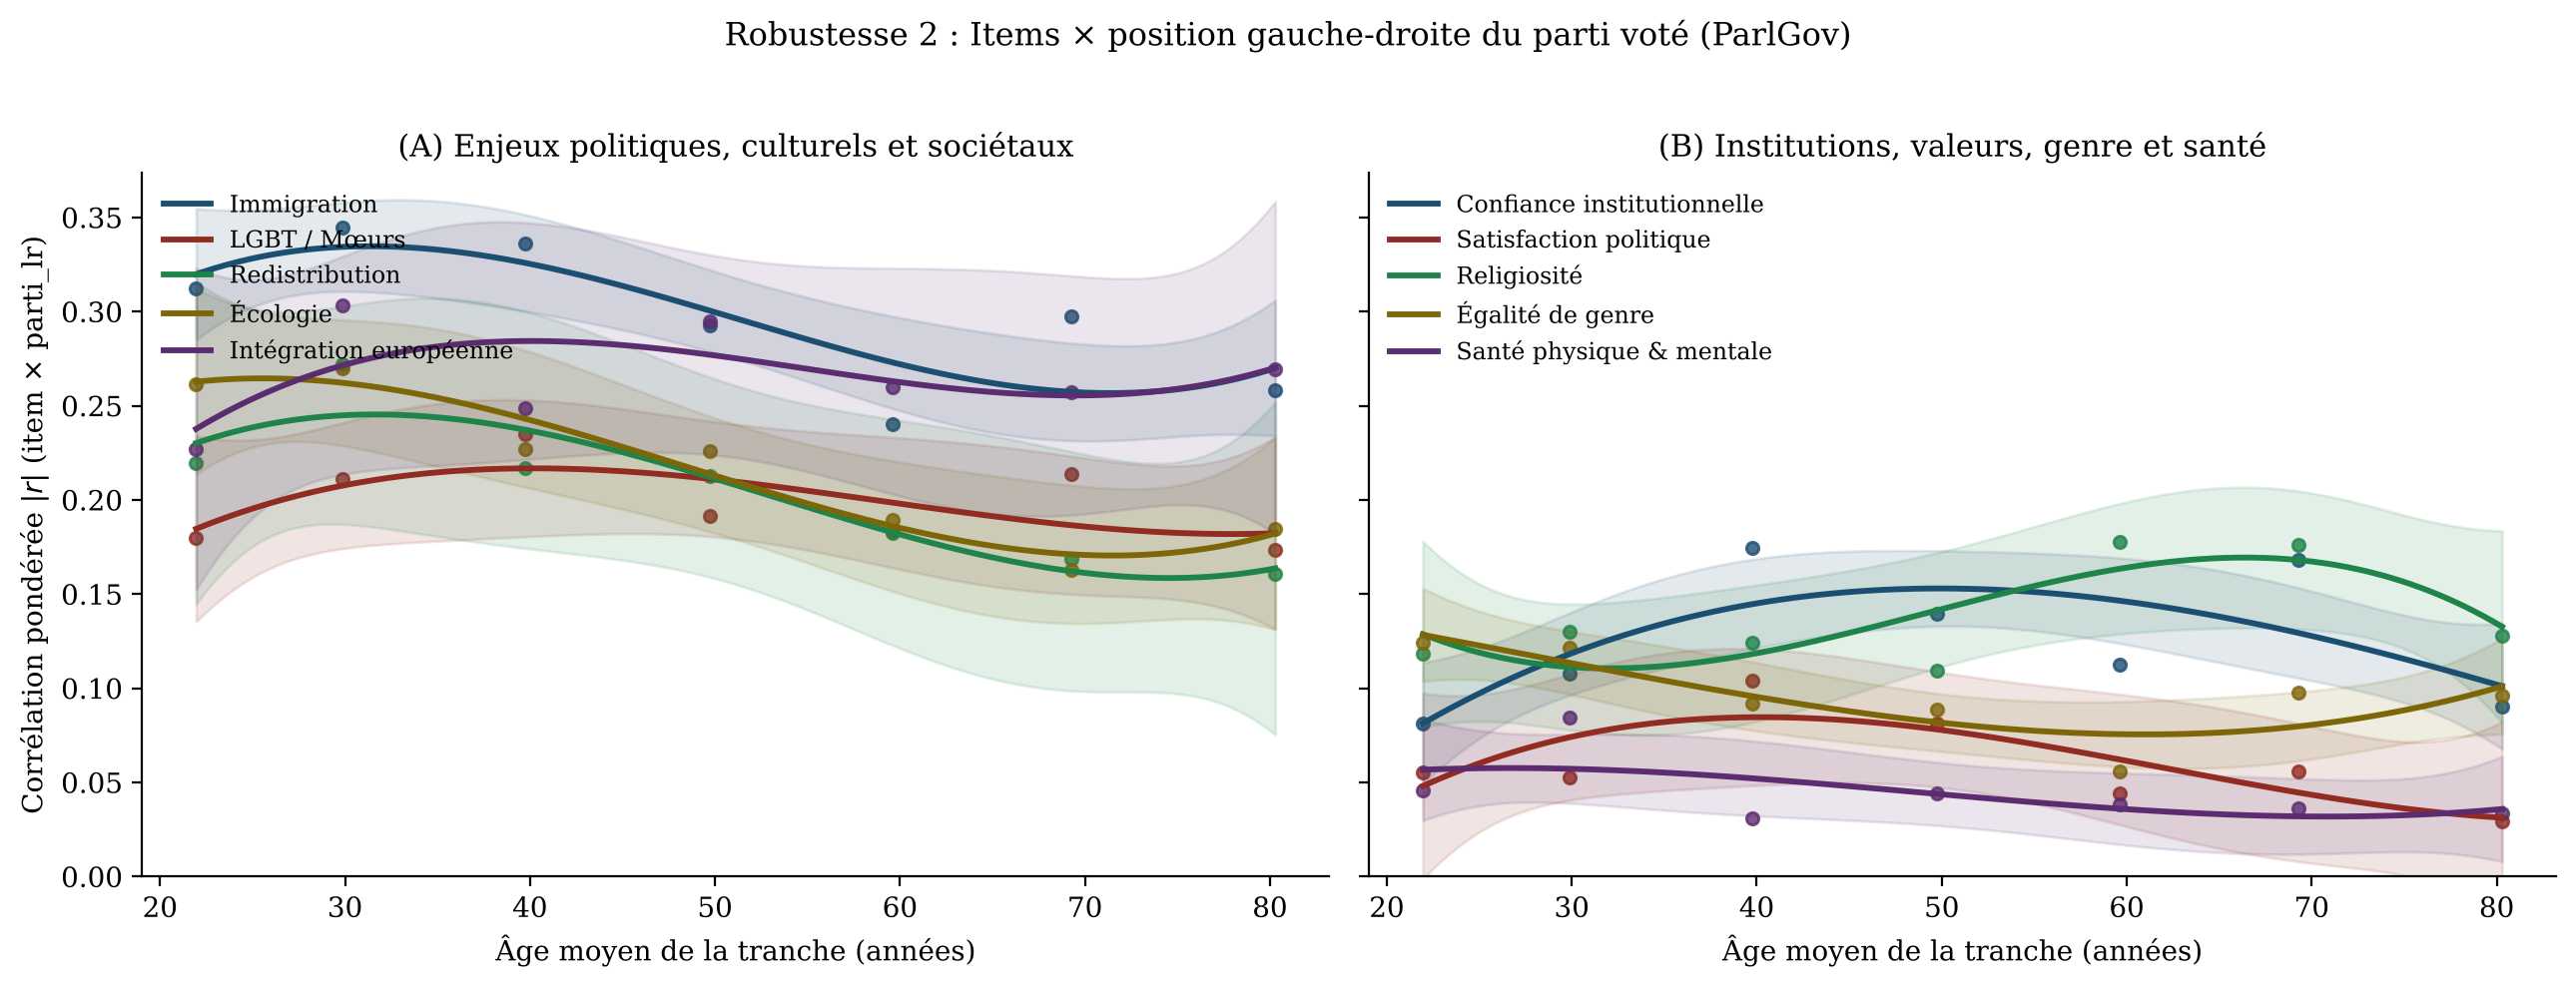

,Moyenne,Ecart_Type,Mediane,Max
label,,,,
Immigration,0.297,0.046,0.304,0.390
Intégration européenne,0.266,0.026,0.260,0.303
Écologie,0.217,0.058,0.213,0.357
Redistribution,0.205,0.038,0.212,0.272
LGBT / Mœurs,0.198,0.068,0.179,0.318
Religiosité,0.138,0.039,0.142,0.204
Confiance institutionnelle,0.125,0.062,0.107,0.274
Égalité de genre,0.097,0.052,0.094,0.210
Satisfaction politique,0.060,0.039,0.053,0.146


In [28]:
# Robustesse 2 : Positionnement gauche-droite du parti voté (ParlGov)
_, summary_pg = alignement.analyser_alignement_age_thematiques(
    df_ess[df_ess["parti_lr"].notna()], alignement.GROUPES_ITEMS, weight_col, target_col="parti_lr",
    titre="Robustesse 2 : Items × position gauche-droite du parti voté (ParlGov)",
    ylabel=r"Corrélation pondérée $|r|$ (item $\times$ parti_lr)",
    nom_png="fig09_robustesse_parti_parlgov.png",
)
plt.show()
summary_pg

#### Robustesse 1 : Indices thématiques agrégés

L'agrégation des items en indices standardisés par thème confirme les résultats principaux tout en corrigeant le biais d'atténuation lié au bruit de mesure des questions isolées :

* **Renforcement de l'alignement sur les thèmes multi-items :** La réduction de la variance d'échantillonnage relève sensiblement les corrélations sur les dimensions composées de plusieurs indicateurs (en particulier l'**immigration**, l'**égalité de genre** et l'**écologie**), tandis que les thèmes à item unique (**redistribution**, **intégration européenne**) restent inchangés et que le thème témoin (**santé**) demeure proche de zéro.
* **Stabilité des profils selon l'âge :** L'ensemble des trajectoires générationnelles observées sur les items bruts est préservé (décroissance avec l'âge pour l'immigration, l'écologie et le genre ; stabilité pour les enjeux sociétaux et européens ; hausse pour la religiosité).

#### Robustesse 2 : Position gauche-droite du parti voté (ParlGov)

En remplaçant l'auto-placement subjectif (`lrscale`) par le score gauche-droite attribué par des experts au parti voté (`parti_lr`, sur les $N = \text{18 899}$ électeurs appariés), ce test limite les biais liés à l'auto-étiquetage idéologique :

* **Confirmation dans les urnes :** La hiérarchie des enjeux structurants du Panneau (A) est retrouvée, avec l'**immigration** en tête devant l'**intégration européenne**, dont le poids s'avère encore plus marqué dans le choix partisan que dans l'auto-identification gauche-droite.
* **Nuances selon l'âge et rapport aux institutions :** Chez les jeunes électeurs, l'alignement entre opinions et vote partisan se cristallise progressivement entre 22 et 35 ans, tandis que l'alignement sur l'immigration reste élevé chez les électeurs âgés. Dans le Panneau (B), la **confiance institutionnelle** apparaît davantage liée au parti voté qu'à l'auto-placement, traduisant la captation de la défiance politique par des partis situés aux extrêmes de l'échelle ParlGov.

In [29]:
alignement.effectifs_partie3(df_ess)

Nombre de pays                     28
N (lrscale valide)              40114
N ParlGov (parti voté relié)    18899
dtype: int64

### 3.5 Conclusion de la partie 3

La simulation de Baldassarri et Gelman (2008) montre qu'un simple alignement corrélé entre opinions suffit à produire une polarisation agrégée (écartement entre camps et homogénéisation interne) sans radicalisation marginale sur chaque sujet pris isolément.

Appliquée aux données transversales d'ESS11 sur 28 pays européens ($N = \text{40 114}$), l'estimation par polynômes de degré 3 met en évidence trois enseignements :
* **Une structuration multidimensionnelle de l'axe gauche-droite :** Le clivage idéologique en Europe est dominé par l'immigration, suivie des enjeux culturels (LGBT / mœurs), de la redistribution économique, de l'intégration européenne et de l'écologie, tandis que le thème témoin (santé) reste non aligné et que la confiance institutionnelle masque des oppositions de signes entre pays.
* **Des profils contrastés selon l'âge :** Loin d'un alignement uniformément croissant avec l'âge, les jeunes cohortes présentent une structuration plus marquée sur l'immigration, l'écologie et l'égalité de genre, alors que les enjeux sociétaux, économiques et européens restent relativement stables et que seule la religiosité s'aligne davantage aux âges élevés.
* **Une robustesse confirmée :** L'agrégation en indices thématiques confirme ces dynamiques en réduisant le biais d'atténuation, et le croisement avec le score ParlGov des partis votés  atteste que cet alignement — en particulier sur l'immigration et l'intégration européenne — se traduit dans le comportement électoral.

<a id="conclusion"></a>
## Conclusion

**Ce que nous retenons.**
1. **Les Européens sont peu polarisés au sens de l'extrémité :** un tiers se place exactement au centre et seuls 13 % aux extrêmes. L'extrémité n'est pas réservée à l'Est (Pologne et Hongrie en tête, mais aussi la Suède, la Norvège et la Finlande).
2. **Les opinions sont faiblement mais systématiquement liées entre elles,** même entre sujets sans rapport logique (immigration et droits LGBT), et la démographie ne l'explique pas : c'est le résultat de DellaPosta et al., retrouvé en Europe.
3. **La position gauche-droite combine un axe économique et un axe culturel.** Pays par pays, la redistribution et l'immigration sont les sujets les plus liés à la position ; l'extrémité, elle, est surtout liée au rapport au système (Europe, institutions, satisfaction).
4. **Ces liens dépendent du pays et de l'âge.** Ils s'inversent dans plusieurs pays de l'Est. Selon l'âge, l'alignement sur l'immigration, l'écologie et l'égalité de genre est plus fort chez les jeunes adultes, alors que celui sur la religion augmente avec l'âge. La simulation de Baldassarri et Gelman rappelle qu'un tel alignement suffit à creuser l'écart entre camps, sans que personne ne devienne plus extrême.

**Limites.**
- Des corrélations, pas des relations de cause à effet.
- Une seule vague d'enquête : on compare des générations à une date donnée, sans pouvoir séparer l'effet de l'âge de celui de la génération.
- Une forte non-réponse à l'échelle gauche-droite dans certains pays (Serbie, Lettonie).
- La partie 2 calcule les corrélations pays par pays, la partie 3 mélange les pays : les niveaux ne sont donc pas directement comparables (la partie 2 montre que mélanger les pays gonfle certains liens).

**Pour aller plus loin.**
- Refaire l'analyse sur les vagues précédentes de l'ESS pour suivre l'alignement dans le temps, comme Kozlowski et Murphy.
- Utiliser les indicateurs Eurostat récupérés en partie 1 (PIB, inégalités, chômage) pour voir si les pays plus inégalitaires sont plus polarisés.

<a id="references"></a>
## Références

- Baldassarri, D. et Gelman, A. (2008). Partisans without Constraint: Political Polarization and Trends in American Public Opinion. *American Journal of Sociology*, 114(2).
- DellaPosta, D., Shi, Y. et Macy, M. (2015). Why Do Liberals Drink Lattes? *American Journal of Sociology*, 120(5).
- Kozlowski, A. C. et Murphy, J. P. (2021). Issue Alignment and Partisanship in the American Public: Revisiting the "Partisans without Constraint" Thesis. *Social Science Research*, 94.
- ESS ERIC (2024). *European Social Survey Round 11*, édition 4.2. Licence CC BY-NC-SA 4.0.
- Döring, H. et Manow, P. *ParlGov* : Parliaments and governments database.
- Döring, H. et Regel, S. (2019). Party Facts: A database of political parties worldwide. *Party Politics*, 25(2).
- Eurostat, API de diffusion (indicateurs `tec00114`, `ilc_di12`, `une_rt_a`).